# Análisis descriptivo del mercado: empresas del Dow Jones (2016-2025)

Dataset de entrada:
- `Datos/Transformados/dowjones_diario_2016_2025.csv` -> dataset limpio: una vela diaria
  (open, high, low, close, volume) por empresa y día de mercado, precios ajustados por splits.

Dataset de salida:
- `Datos/Transformados/resumen_descriptivo_empresas.csv` -> una fila por empresa con sus métricas de
  rentabilidad, riesgo y relación con el mercado (punto de partida para seleccionar la cartera).

Objetivo: describir **el mercado en su conjunto**, no cada acción por separado. El análisis detallado de
las acciones se hará después, sobre las que entren en la cartera.

El orden va de menos a más técnico:

| # | Sección | Qué responde |
|---|---|---|
| 1 | Panorama del universo | Qué empresas, de qué sectores y con qué historial |
| 2 | Evolución del mercado | Cómo se ha comportado el conjunto y frente al Dow Jones real |
| 3 | Rentabilidad por empresa y año | Quién ha ganado y quién ha perdido, y cuándo |
| 4 | Volumen negociado | Dónde está la liquidez y cuándo se dispara |
| 5 | Rentabilidades diarias | Cómo se distribuyen: medias, colas, días extremos |
| 6 | Volatilidad | Cuánto riesgo hay y cómo cambia en el tiempo |
| 7 | Riesgo frente a rentabilidad | Qué empresas compensan su riesgo (Sharpe, Sortino) |
| 8 | Drawdowns | Cuánto se puede llegar a perder y cuánto se tarda en recuperar |
| 9 | Correlaciones | Cuánto se mueven juntas y si eso cambia en las crisis |
| 10 | Beta frente al mercado | Sensibilidad de cada empresa al mercado |
| 11 | Hechos estilizados y PCA | Memoria de la volatilidad y cuántos factores mueven el mercado |
| 12 | Tabla resumen | Todas las métricas juntas, para la selección de la cartera |

**Decisiones de partida (afectan a cómo se leen todos los resultados):**

- **Rentabilidad de precio, no total.** El cierre viene ajustado por splits pero no por dividendos.
  En empresas con dividendo alto (KO, PG, JNJ, CVX, IBM...) la rentabilidad total es
  bastante mayor. En la sección 3 se compara con el `Adj Close` de Yahoo si se puede descargar.
- **"Mercado" = índice propio equiponderado** de todas las empresas del dataset (media diaria de sus rentabilidades).
  Siempre está disponible y pesa igual a todas. Se compara con un índice ponderado por precio (la
  metodología del Dow Jones) y con el `^DJI` real.
- **No es el Dow Jones de todo el periodo.** Las empresas del dataset son una foto fija de su composición,
  pero el índice ha cambiado varias veces entre 2016 y 2025 (entradas y salidas de miembros). Hay, por tanto,
  sesgo de composición: conviene comprobar los cambios del índice antes de citarlos.
- **Rentabilidades simples** para construir índices y acumular; **logarítmicas** para estadísticos,
  volatilidad, correlaciones y PCA.

In [66]:
import os
import warnings

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from matplotlib.patches import Patch
from scipy import stats
from scipy.cluster.hierarchy import leaves_list, linkage
from scipy.spatial.distance import squareform
import yfinance as yf

warnings.filterwarnings("ignore", category=RuntimeWarning)

In [35]:
# Rutas y parámetros
RUTA_DATOS = "Datos/Transformados/dowjones_diario_2016_2025.csv"
RUTA_TRANSFORMADOS = "Datos/Transformados"
FECHA_INICIO = "2016-01-01"
FECHA_FIN = "2026-01-01"          # exclusivo en yfinance (incluye hasta 2025-12-31)

DIAS_ANIO = 252                   # sesiones por año para anualizar
TASA_LIBRE_DEFECTO = 0.02         # solo si no se puede descargar la letra del Tesoro (^IRX)
VENTANA_CORTA, VENTANA_LARGA = 21, 63   # ~1 mes y ~1 trimestre de sesiones

# Episodios de caída del mercado que se sombrean en los gráficos (fechas aproximadas del Dow Jones)
EPISODIOS = {
    "Ventas fin 2018": ("2018-10-03", "2018-12-24"),
    "COVID-19": ("2020-02-12", "2020-03-23"),
    "Subida de tipos": ("2022-01-04", "2022-09-30"),
    "Aranceles 2025": ("2025-04-02", "2025-04-08"),
}

In [36]:
# Estilo de los gráficos: colores y formato comunes a todo el notebook
AZUL, NARANJA, VERDE, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#898781"
ROJO = "#e34948"
FONDO, TINTA, TINTA_2 = "#fcfcfb", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.facecolor": FONDO, "axes.facecolor": FONDO, "savefig.facecolor": FONDO,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": TINTA_2, "text.color": TINTA,
    "xtick.color": TINTA_2, "ytick.color": TINTA_2, "axes.grid": True, "grid.color": "#e1e0d9",
    "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 10.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "figure.titlesize": 12, "figure.titleweight": "bold",
    "lines.linewidth": 2, "legend.frameon": False, "font.size": 9.5,
})
pd.set_option("display.width", 200)

# Sectores: un color fijo por sector, siempre el mismo en todos los gráficos.
# Energía, Comunicación y Materiales tienen una sola empresa cada uno y se agrupan en "Otros".
SECTOR = {
    "AAPL": "Tecnología", "CRM": "Tecnología", "CSCO": "Tecnología", "IBM": "Tecnología",
    "INTC": "Tecnología", "MSFT": "Tecnología",
    "AXP": "Financiero", "GS": "Financiero", "JPM": "Financiero", "TRV": "Financiero",
    "V": "Financiero",            # GICS la pasó de Tecnología a Financiero en 2023
    "AMGN": "Salud", "JNJ": "Salud", "MRK": "Salud", "UNH": "Salud",
    "BA": "Industrial", "CAT": "Industrial", "MMM": "Industrial",
    "HD": "Consumo discrecional", "MCD": "Consumo discrecional", "NKE": "Consumo discrecional",
    "KO": "Consumo básico", "PG": "Consumo básico",
    "CVX": "Otros", "DIS": "Otros", "DOW": "Otros",
    # Otros miembros del Dow en 2016-2025, por si el dataset los incluye
    "HON": "Industrial", "NVDA": "Tecnología", "AMZN": "Consumo discrecional", "WMT": "Consumo básico",
    "WBA": "Consumo básico", "VZ": "Otros", "SHW": "Otros", "XOM": "Otros", "PFE": "Salud",
    "RTX": "Industrial", "UTX": "Industrial", "GE": "Industrial", "DD": "Otros", "DWDP": "Otros",
}
SUBSECTOR_OTROS = {"CVX": "Energía", "DIS": "Comunicación", "DOW": "Materiales", "VZ": "Comunicación",
                   "SHW": "Materiales", "XOM": "Energía", "DD": "Materiales", "DWDP": "Materiales"}
COLOR_SECTOR = {
    "Tecnología": "#2a78d6", "Financiero": "#eb6834", "Salud": "#1baf7a", "Industrial": "#eda100",
    "Consumo discrecional": "#e87ba4", "Consumo básico": "#008300", "Otros": "#4a3aa7",
}
NOMBRE = {
    "AAPL": "Apple", "AMGN": "Amgen", "AXP": "American Express", "BA": "Boeing", "CAT": "Caterpillar",
    "CRM": "Salesforce", "CSCO": "Cisco", "CVX": "Chevron", "DIS": "Disney", "DOW": "Dow Inc.",
    "GS": "Goldman Sachs", "HD": "Home Depot", "IBM": "IBM", "INTC": "Intel", "JNJ": "Johnson & Johnson",
    "JPM": "JPMorgan", "KO": "Coca-Cola", "MCD": "McDonald's", "MMM": "3M", "MRK": "Merck",
    "MSFT": "Microsoft", "NKE": "Nike", "PG": "Procter & Gamble", "TRV": "Travelers",
    "UNH": "UnitedHealth", "V": "Visa", "HON": "Honeywell", "NVDA": "Nvidia", "AMZN": "Amazon",
    "WMT": "Walmart", "WBA": "Walgreens", "VZ": "Verizon", "SHW": "Sherwin-Williams", "XOM": "ExxonMobil",
    "PFE": "Pfizer", "RTX": "RTX", "UTX": "United Technologies", "GE": "General Electric", "DD": "DuPont",
    "DWDP": "DowDuPont",
}

# Divergente rojo (negativo) - gris (cero) - azul (positivo), para rentabilidades
DIVERGENTE = LinearSegmentedColormap.from_list(
    "divergente", ["#a3292b", ROJO, "#f3b3b2", "#f0efec", "#9ec5f4", AZUL, "#184f95"])
SECUENCIAL = LinearSegmentedColormap.from_list(
    "secuencial", ["#f0efec", "#cde2fb", "#86b6ef", AZUL, "#1c5cab", "#0d366b"])


def color(ticker):
    return COLOR_SECTOR[SECTOR.get(ticker, "Otros")]


def sombrear_episodios(ax, etiquetas=False):
    """Sombrea los episodios de caída; con etiquetas=True escribe el nombre arriba."""
    for nombre, (ini, fin) in EPISODIOS.items():
        ax.axvspan(pd.Timestamp(ini), pd.Timestamp(fin), color=GRIS, alpha=0.13, lw=0)
        if etiquetas:
            ax.text(pd.Timestamp(ini), 0.99, nombre, transform=ax.get_xaxis_transform(),
                    fontsize=7.5, color=TINTA_2, va="top", ha="left", rotation=90)


def leyenda_sectores(ax, **kwargs):
    """Leyenda de sectores; por defecto fuera del gráfico, a la derecha, para no tapar barras."""
    opciones = {"loc": "center left", "bbox_to_anchor": (1.01, 0.5), "fontsize": 8.5, **kwargs}
    ax.legend(handles=[Patch(color=c, label=s) for s, c in COLOR_SECTOR.items()], **opciones)


def eje_pct(ax, eje="y", decimales=0):
    formato = mtick.PercentFormatter(1, decimals=decimales)
    (ax.yaxis if eje == "y" else ax.xaxis).set_major_formatter(formato)


def descargar_yahoo(tickers, campos):
    """Descarga de Yahoo los campos pedidos. Devuelve {campo: DataFrame} o None si no se puede."""
    if yf is None:
        print("yfinance no está instalado: se omite la comparación con Yahoo.")
        return None
    try:
        datos = yf.download(tickers, start=FECHA_INICIO, end=FECHA_FIN, auto_adjust=False,
                            progress=False, threads=True)
        if datos is None or datos.empty:
            raise ValueError("descarga vacía")
        salida = {}
        for campo in campos:
            tabla = datos[campo]
            if isinstance(tabla, pd.Series):
                tabla = tabla.to_frame(tickers[0])
            indice = pd.to_datetime(tabla.index)
            if indice.tz is not None:
                indice = indice.tz_convert(None)
            tabla.index = indice.normalize()
            salida[campo] = tabla
        return salida
    except Exception as error:
        print(f"No se pudo descargar {tickers[:3]}... de Yahoo ({error}): se omite esa comparación.")
        return None

# 1. Panorama del universo: qué empresas, de qué sectores y con qué historial

In [37]:
df = pd.read_csv(RUTA_DATOS, parse_dates=["date"]).sort_values(["symbol", "date"])
empresas = sorted(df["symbol"].unique())
print(f"{len(df):,} filas | {len(empresas)} empresas | {df['date'].min().date()} a {df['date'].max().date()}")
print("Nulos:", int(df.isna().sum().sum()), "| Duplicados symbol+date:", int(df.duplicated(["symbol", "date"]).sum()))

# Tablas anchas (una columna por empresa): son la base de todo el análisis
precios = df.pivot(index="date", columns="symbol", values="close").sort_index()
volumen = df.pivot(index="date", columns="symbol", values="volume").sort_index()
rent = precios.pct_change(fill_method=None)            # rentabilidad simple diaria
rent_log = np.log(precios).diff()                       # rentabilidad logarítmica diaria

desconocidas = [t for t in empresas if t not in SECTOR]
if desconocidas:
    print("Empresas sin sector asignado (van a 'Otros'; añádelas a SECTOR si quieres):", desconocidas)
SECTOR = {t: SECTOR.get(t, "Otros") for t in empresas}       # solo las empresas del dataset
NOMBRE = {t: NOMBRE.get(t, t) for t in empresas}
COLOR_SECTOR = {s: c for s, c in COLOR_SECTOR.items() if s in SECTOR.values()}   # solo sectores presentes
N = len(empresas)
orden_sector = sorted(empresas, key=lambda t: (list(COLOR_SECTOR).index(SECTOR[t]), t))
print(f"{N} empresas:", ", ".join(orden_sector))

72,099 filas | 29 empresas | 2016-01-04 a 2025-12-31
Nulos: 0 | Duplicados symbol+date: 0
29 empresas: AAPL, CRM, CSCO, IBM, INTC, MSFT, AXP, GS, JPM, TRV, V, AMGN, JNJ, MRK, UNH, BA, CAT, HON, MMM, HD, MCD, NKE, KO, PG, WMT, CVX, DIS, DOW, VZ


In [38]:
panorama = df.groupby("symbol").agg(
    inicio=("date", "min"), fin=("date", "max"), sesiones=("date", "size"),
    precio_inicial=("close", "first"), precio_final=("close", "last"))
panorama.insert(0, "nombre", panorama.index.map(NOMBRE))
panorama.insert(1, "sector", panorama.index.map(lambda t: SUBSECTOR_OTROS.get(t, SECTOR[t])))
panorama["inicio"] = panorama["inicio"].dt.date
panorama["fin"] = panorama["fin"].dt.date
print(panorama.loc[orden_sector].round(2).to_string())

sesiones_anio = precios.notna().groupby(precios.index.year).sum()
print("\nSesiones por año (mínimo y máximo entre empresas):")
print(sesiones_anio.agg(["min", "max"], axis=1).T.to_string())

                   nombre                sector      inicio         fin  sesiones  precio_inicial  precio_final
symbol                                                                                                         
AAPL                Apple            Tecnología  2016-01-04  2025-12-31      2514           26.34        271.86
CRM            Salesforce            Tecnología  2016-01-04  2025-12-31      2514           76.71        264.91
CSCO                Cisco            Tecnología  2016-01-04  2025-12-31      2514           26.41         77.03
IBM                   IBM            Tecnología  2016-01-04  2025-12-31      2514          129.97        296.21
INTC                Intel            Tecnología  2016-01-04  2025-12-31      2514           33.99         36.90
MSFT            Microsoft            Tecnología  2016-01-04  2025-12-31      2514           54.80        483.62
AXP      American Express            Financiero  2016-01-04  2025-12-31      2514           67.59       

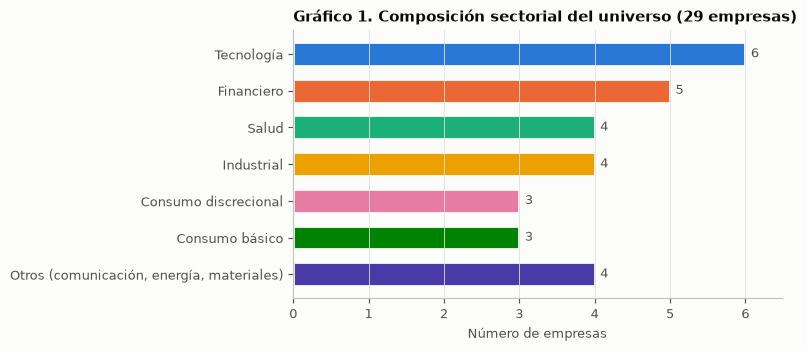

In [ ]:
# Gráfico: cuántas empresas hay de cada sector
conteo = pd.Series(SECTOR).value_counts().reindex(COLOR_SECTOR)[::-1]
etiquetas = [s if s != "Otros" else "Otros (" + ", ".join(sorted({SUBSECTOR_OTROS.get(t, NOMBRE[t]).lower() for t in empresas if SECTOR[t] == "Otros"})) + ")" for s in conteo.index]
fig, ax = plt.subplots(figsize=(8, 3.6))
barras = ax.barh(etiquetas, conteo.values, color=[COLOR_SECTOR[s] for s in conteo.index],
                 height=0.65, edgecolor=FONDO, linewidth=2)
ax.bar_label(barras, padding=4, color=TINTA_2, fontsize=9)
ax.set_xlabel("Número de empresas")
ax.grid(axis="y", visible=False)
ax.margins(x=0.08)
ax.set_title(f"Gráfico 1. Composición sectorial del mercado ({N} empresas)")
plt.tight_layout()
plt.show()

**Qué mirar:**
- El peso de cada sector: con un índice equiponderado, un sector con 6 de N empresas pesa 6/N en el "mercado".
  Si tecnología y financiero suman casi la mitad, el índice estará muy expuesto a ellos.
- Qué empresas no tienen el historial completo (columna `inicio` de la tabla). Por ejemplo, DOW cotiza desde
  el 20/03/2019, cuando se separó de DowDuPont. Las métricas de esas empresas se calculan sobre un periodo más
  corto y no son del todo comparables con las demás.

Se observa que los principales sectores del mercado son tanto el tecnológico como el financiero constituyendo casi un 40% de las empresas, estando por encima de sectores como el indutrial o el de la salud.

# 2. Evolución del mercado: índice propio frente al Dow Jones real

In [67]:
# Índice equiponderado: cada día, media de las rentabilidades de las empresas que cotizan
rent_mercado = rent.mean(axis=1, skipna=True).iloc[1:]
indice_ew = 100 * (1 + rent_mercado).cumprod()
indice_ew = pd.concat([pd.Series([100.0], index=[precios.index[0]]), indice_ew])
rent_log_mercado = np.log1p(rent_mercado)

# Dow Jones real, rebasado a 100 el primer día, para comparar
yahoo_dji = descargar_yahoo(["^DJI"], ["Close"])
dji = None
if yahoo_dji is not None:
    dji = yahoo_dji["Close"]["^DJI"].reindex(precios.index).ffill().dropna()
    dji = 100 * dji / dji.iloc[0]

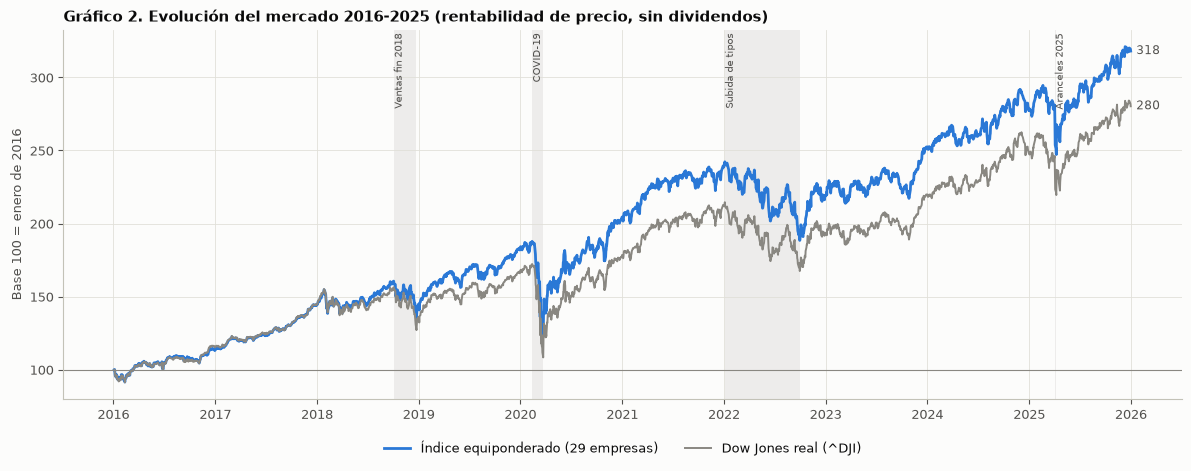

In [68]:
fig, ax = plt.subplots(figsize=(12, 4.8))
sombrear_episodios(ax, etiquetas=True)
ax.plot(indice_ew, color=AZUL, lw=2, label=f"Índice equiponderado ({N} empresas)")
if dji is not None:
    ax.plot(dji, color=GRIS, lw=1.4, label="Dow Jones real (^DJI)")
for serie, col in [(indice_ew, AZUL)] + ([(dji, GRIS)] if dji is not None else []):
    ax.annotate(f"{serie.iloc[-1]:.0f}", (serie.index[-1], serie.iloc[-1]), xytext=(4, 0),
                textcoords="offset points", fontsize=8.5, color=TINTA_2, va="center")
ax.axhline(100, color=GRIS, lw=0.8)
ax.set_ylabel("Base 100 = enero de 2016")
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=2)
ax.set_title("Gráfico 2. Evolución del mercado 2016-2025 (rentabilidad de precio, sin dividendos)")
plt.tight_layout()
plt.show()

      equiponderado  dow_jones_real
date                               
2016           13.1            15.2
2017           27.2            25.1
2018            0.7            -5.6
2019           26.0            22.3
2020           12.1             7.2
2021           16.7            18.7
2022           -8.4            -8.8
2023           15.4            13.7
2024           10.3            12.9
2025           14.3            13.0

Rentabilidad anualizada (CAGR): equiponderado 12.3% | Dow Jones real 10.9%


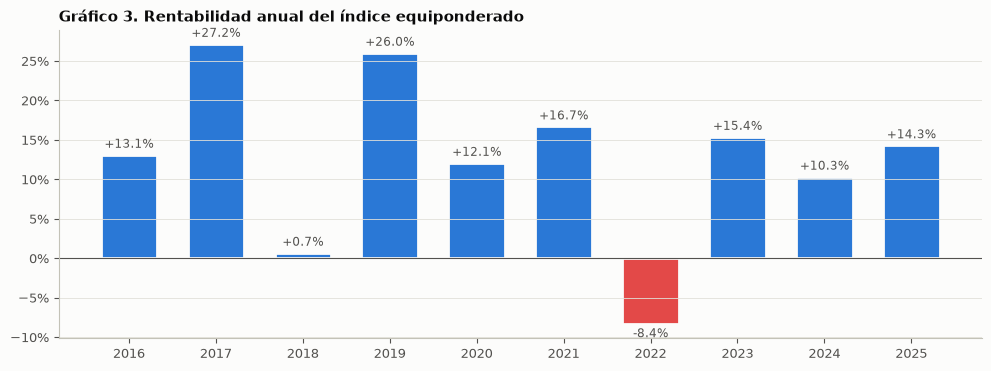

In [70]:
# Rentabilidad anual del mercado (índice equiponderado) y del Dow Jones real
anuales = pd.DataFrame({
    "equiponderado": (1 + rent_mercado).groupby(rent_mercado.index.year).prod() - 1,
})
if dji is not None:
    anuales["dow_jones_real"] = dji.groupby(dji.index.year).last() / dji.groupby(dji.index.year).last().shift() - 1
    anuales.loc[anuales.index.min(), "dow_jones_real"] = dji.groupby(dji.index.year).last().iloc[0] / 100 - 1
print((anuales * 100).round(1).to_string())

anios_total = (indice_ew.index[-1] - indice_ew.index[0]).days / 365.25
print(f"\nRentabilidad anualizada (CAGR): equiponderado {(indice_ew.iloc[-1] / 100) ** (1 / anios_total) - 1:.1%}"
      + (f" | Dow Jones real {(dji.iloc[-1] / 100) ** (1 / anios_total) - 1:.1%}" if dji is not None else ""))

fig, ax = plt.subplots(figsize=(10, 3.8))
valores = anuales["equiponderado"]
barras = ax.bar(valores.index.astype(str), valores, color=np.where(valores >= 0, AZUL, ROJO),
                width=0.65, edgecolor=FONDO, linewidth=2)
ax.bar_label(barras, labels=[f"{v:+.1%}" for v in valores], padding=3, fontsize=8.5, color=TINTA_2)
ax.axhline(0, color=TINTA_2, lw=0.8)
eje_pct(ax)
ax.grid(axis="x", visible=False)
ax.set_title("Gráfico 3. Rentabilidad anual del índice equiponderado")
plt.tight_layout()
plt.show()

**Qué mirar:**
- Si el índice equiponderado sigue de cerca al `^DJI`, el universo del dataset es una buena aproximación
  del mercado; las diferencias vienen de la ponderación, de las 4 empresas que faltan y de los cambios de
  composición.
- El índice ponderado por precio da más peso a las acciones caras (UNH, GS, MSFT, HD...). Si se separa
  mucho del equiponderado, el resultado del mercado depende de pocas empresas grandes.
- Los años negativos y su relación con los episodios sombreados (2018, 2020, 2022).

# 3. Rentabilidad por empresa y año: quién ha ganado, quién ha perdido y cuándo

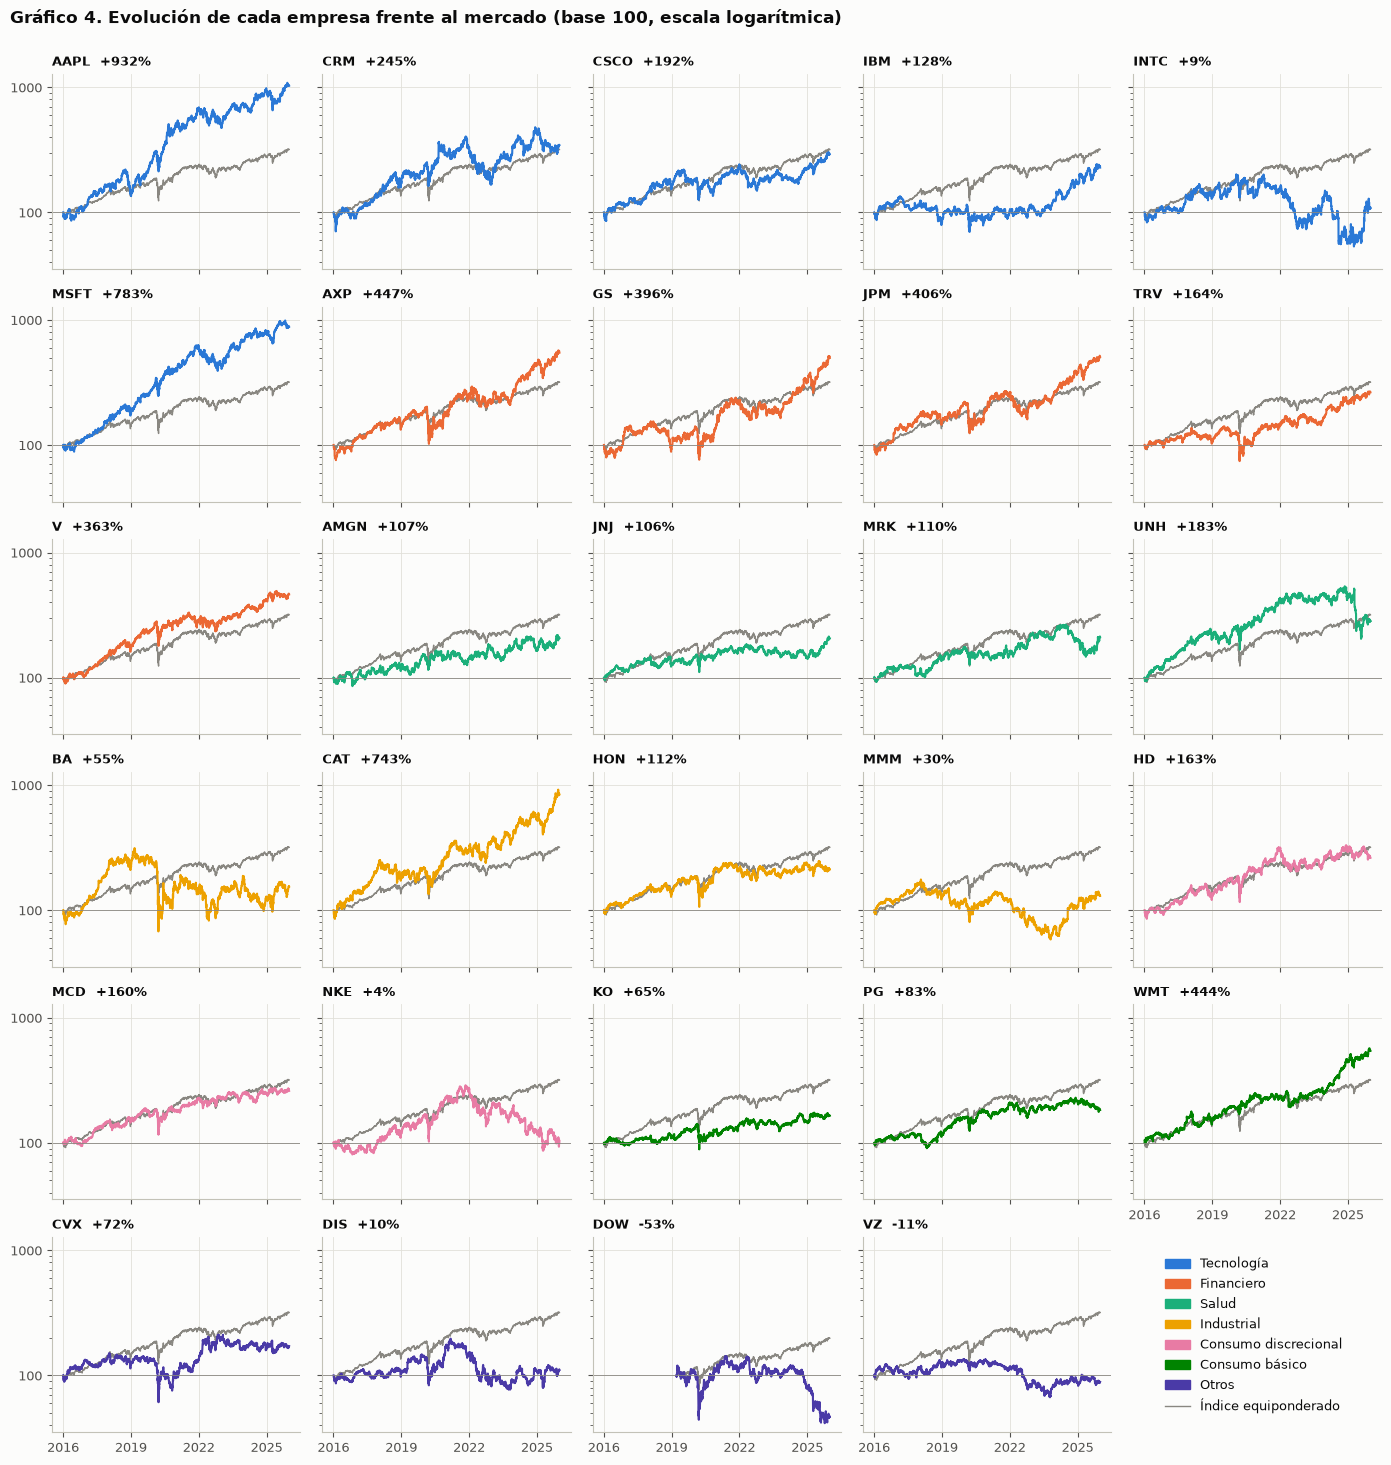

In [43]:
# Pequeños múltiplos: cada empresa (color de su sector) frente al índice (gris), base 100 en su primer día
columnas = 5
filas = int(np.ceil(N / columnas))
fig, ejes = plt.subplots(filas, columnas, figsize=(14, 2.4 * filas + 0.5), sharex=True, sharey=True, squeeze=False)
for ax, ticker in zip(ejes.flat, orden_sector):
    serie = precios[ticker].dropna()
    base_indice = indice_ew.loc[serie.index[0]:]
    ax.plot(100 * base_indice / base_indice.iloc[0], color=GRIS, lw=1)
    ax.plot(100 * serie / serie.iloc[0], color=color(ticker), lw=1.5)
    ax.set_yscale("log")
    ax.set_title(f"{ticker}  {serie.iloc[-1] / serie.iloc[0] - 1:+.0%}", fontsize=9.5)
    ax.axhline(100, color=GRIS, lw=0.6)
for ax in list(ejes.flat)[len(orden_sector):]:
    ax.set_visible(False)
for ax in list(ejes.flat)[len(orden_sector) - columnas:len(orden_sector)]:
    ax.tick_params(labelbottom=True)
ejes[0, 0].yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:g}"))
for ax in ejes.flat:
    ax.xaxis.set_major_locator(mdates.YearLocator(3))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fig.legend(handles=[Patch(color=c, label=s) for s, c in COLOR_SECTOR.items()]
           + [plt.Line2D([], [], color=GRIS, lw=1, label="Índice equiponderado")],
           loc="lower right", bbox_to_anchor=(0.97, 0.03), ncol=1, fontsize=9)
fig.suptitle("Gráfico 4. Evolución de cada empresa frente al mercado (base 100, escala logarítmica)",
             x=0.01, ha="left")
plt.tight_layout(rect=(0, 0, 1, 0.98))
plt.show()

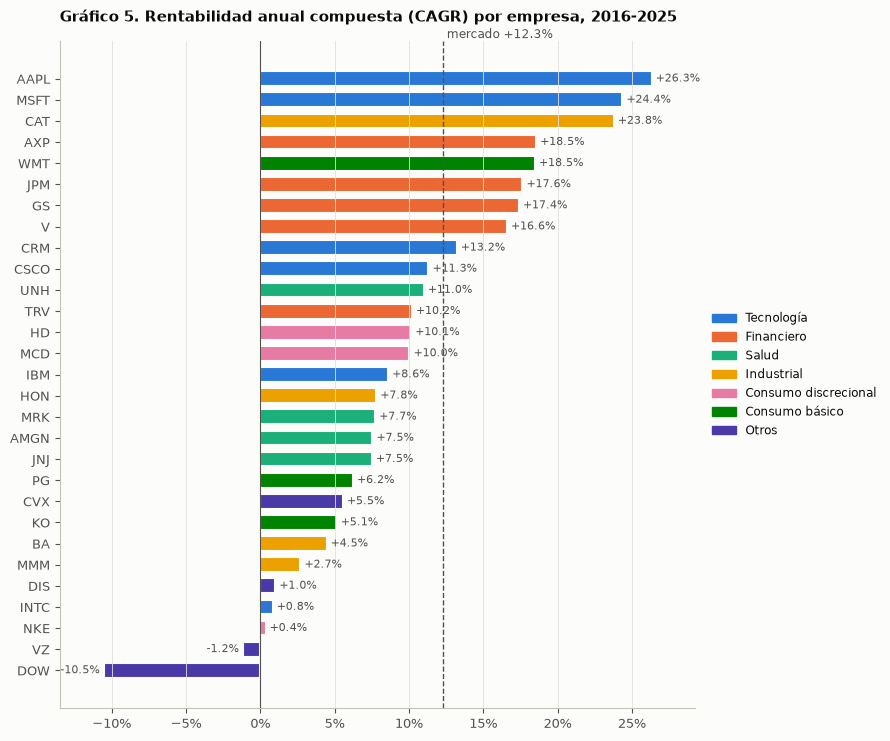

In [44]:
def cagr(serie):
    """Rentabilidad anual compuesta entre el primer y el último precio disponibles."""
    s = serie.dropna()
    anios = (s.index[-1] - s.index[0]).days / 365.25
    return (s.iloc[-1] / s.iloc[0]) ** (1 / anios) - 1


cagr_empresas = precios.apply(cagr).sort_values()
cagr_mercado = cagr(indice_ew)

fig, ax = plt.subplots(figsize=(9, 7.5))
barras = ax.barh(cagr_empresas.index, cagr_empresas, color=[color(t) for t in cagr_empresas.index],
                 height=0.7, edgecolor=FONDO, linewidth=1.5)
ax.bar_label(barras, labels=[f"{v:+.1%}" for v in cagr_empresas], padding=3, fontsize=8, color=TINTA_2)
ax.axvline(cagr_mercado, color=TINTA_2, lw=1, ls="--")
ax.text(cagr_mercado, 1.0, f" mercado {cagr_mercado:+.1%}", transform=ax.get_xaxis_transform(),
        fontsize=8.5, color=TINTA_2, va="bottom")
ax.axvline(0, color=TINTA_2, lw=0.8)
eje_pct(ax, "x")
ax.grid(axis="y", visible=False)
ax.margins(x=0.08)
leyenda_sectores(ax)
ax.set_title("Gráfico 5. Rentabilidad anual compuesta (CAGR) por empresa, 2016-2025", pad=14)
plt.tight_layout()
plt.show()

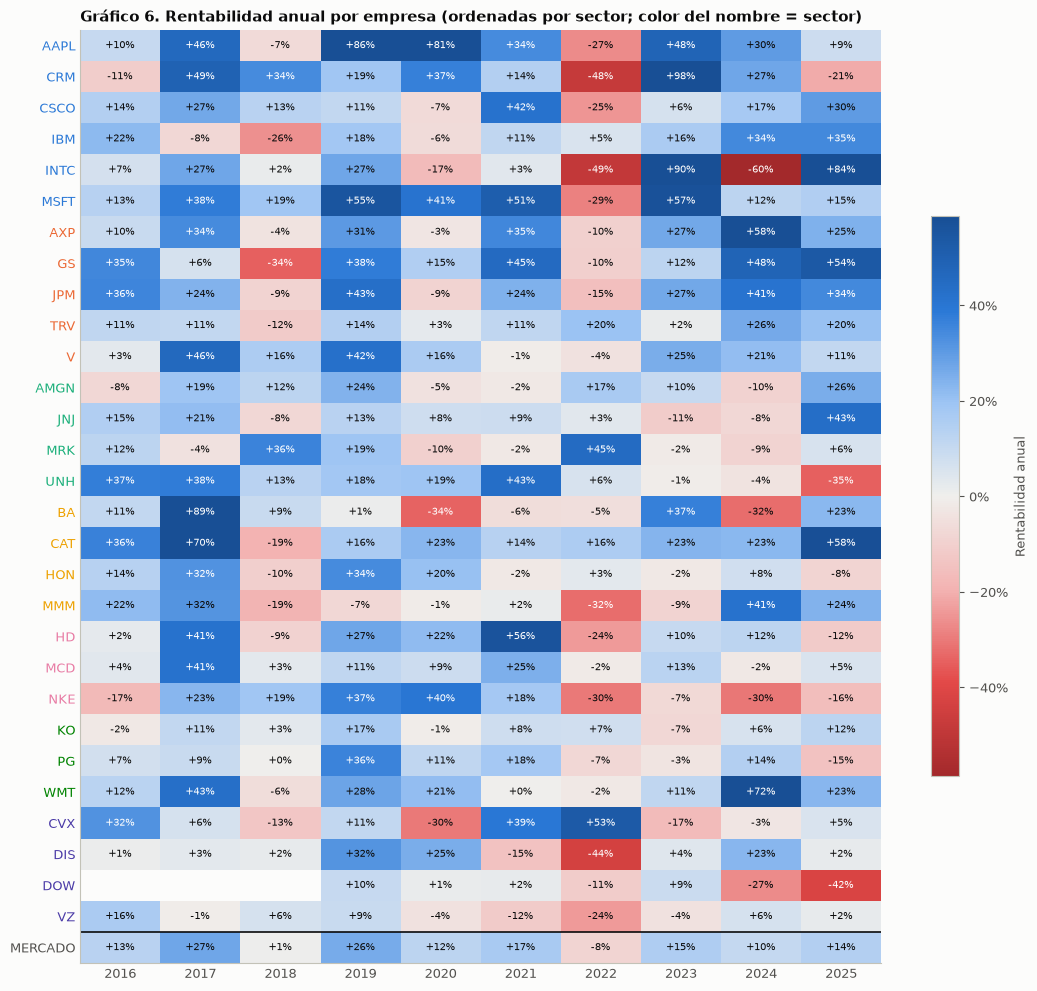

Años en los que más de la mitad de las empresas pierde: [2022]


In [45]:
# Rentabilidad de cada año por empresa (DOW: 2019 parcial, desde el 20/03)
anual_empresas = (1 + rent).groupby(rent.index.year).prod(min_count=1) - 1
anual_empresas = anual_empresas.where(precios.notna().groupby(precios.index.year).sum() > 1)
tabla = anual_empresas[orden_sector].T
tabla.loc["MERCADO"] = anuales["equiponderado"]

limite = np.nanpercentile(np.abs(tabla.values), 97)
fig, ax = plt.subplots(figsize=(11, 10))
imagen = ax.imshow(tabla.values, cmap=DIVERGENTE, norm=TwoSlopeNorm(0, -limite, limite), aspect="auto")
for i in range(tabla.shape[0]):
    for j in range(tabla.shape[1]):
        v = tabla.values[i, j]
        if np.isfinite(v):
            ax.text(j, i, f"{v:+.0%}", ha="center", va="center", fontsize=7.5,
                    color="white" if abs(v) > 0.55 * limite else TINTA)
ax.set_xticks(range(tabla.shape[1]), tabla.columns)
ax.set_yticks(range(tabla.shape[0]), tabla.index)
ax.axhline(tabla.shape[0] - 1.5, color=TINTA, lw=1.2)
for etiqueta in ax.get_yticklabels()[:-1]:
    etiqueta.set_color(color(etiqueta.get_text()))
ax.grid(False)
ax.tick_params(length=0)
fig.colorbar(imagen, ax=ax, format=mtick.PercentFormatter(1, 0), shrink=0.6, label="Rentabilidad anual")
ax.set_title("Gráfico 6. Rentabilidad anual por empresa (ordenadas por sector; color del nombre = sector)")
plt.tight_layout()
plt.show()

print("Años en los que más de la mitad de las empresas pierde:",
      [int(a) for a, v in (anual_empresas < 0).mean(axis=1).items() if v > 0.5])

In [46]:
# Rentabilidad de precio frente a rentabilidad total (con dividendos), si Yahoo está disponible
yahoo_empresas = descargar_yahoo(empresas, ["Adj Close", "Volume"])
if yahoo_empresas is not None:
    ajustado = yahoo_empresas["Adj Close"].reindex(columns=empresas)
    comparacion_div = pd.DataFrame({
        "cagr_precio": cagr_empresas,
        "cagr_total": ajustado.apply(cagr),
    })
    comparacion_div["aporte_dividendo"] = comparacion_div["cagr_total"] - comparacion_div["cagr_precio"]
    comparacion_div = comparacion_div.sort_values("aporte_dividendo", ascending=False)
    print((comparacion_div * 100).round(2).to_string())
    print(f"\nAporte medio del dividendo: {comparacion_div['aporte_dividendo'].mean():.2%} al año")

      cagr_precio  cagr_total  aporte_dividendo
VZ          -1.18        4.12              5.30
DOW        -10.55       -5.42              5.12
IBM          8.59       13.31              4.72
CVX          5.55       10.17              4.62
MMM          2.69        6.14              3.45
CSCO        11.31       14.71              3.40
MRK          7.72       11.10              3.38
KO           5.13        8.49              3.36
AMGN         7.54       10.79              3.25
JPM         17.63       20.78              3.15
CAT         23.78       26.85              3.07
JNJ          7.50       10.52              3.02
PG           6.23        9.19              2.96
MCD         10.03       12.75              2.71
HD          10.14       12.80              2.66
TRV         10.19       12.64              2.44
GS          17.39       19.82              2.43
INTC         0.83        3.23              2.40
HON          7.79       10.06              2.27
WMT         18.47       20.65           

**Qué mirar:**
- La dispersión entre empresas (gráfico 5): la diferencia entre la mejor y la peor es lo que se juega al
  seleccionar la cartera.
- Si las empresas de un mismo sector se mueven juntas (gráfico 4) y si los mismos sectores ganan o pierden
  cada año (gráfico 6). Una columna casi entera en rojo es un año de caída generalizada (riesgo de mercado);
  una fila en rojo es un problema de la empresa (riesgo específico).
- Cuánto cambia el orden al sumar los dividendos: las empresas con dividendo alto quedan infravaloradas si
  solo se mira el precio.

# 4. Volumen negociado: dónde está la liquidez y cuándo se dispara

In [47]:
# Comprobación previa: en algunos días del tramo intradía (2020-2021) el volumen puede ser solo el negociado
# en una bolsa (IEX), una pequeña fracción del total. Buscamos días con un volumen anormalmente bajo frente
# a su mediana trimestral.
mediana_movil = volumen.rolling(VENTANA_LARGA, min_periods=20, center=True).median()
ratio_volumen = volumen / mediana_movil
sospechosos = (ratio_volumen < 0.2).stack()
sospechosos = sospechosos[sospechosos]
print(f"Días-empresa con volumen < 20 % de su mediana trimestral: {len(sospechosos)}")
if len(sospechosos):
    fechas = sospechosos.index.get_level_values("date")
    print(pd.Series(fechas.to_period("M")).value_counts().sort_index().to_string())

if yahoo_empresas is not None:
    vol_yahoo = yahoo_empresas["Volume"].reindex(index=volumen.index, columns=empresas)
    cociente = (volumen / vol_yahoo).stack()
    print(f"\nVolumen del dataset / volumen de Yahoo: mediana {cociente.median():.2f} | "
          f"días con cociente < 0,2: {(cociente < 0.2).sum()}")

Días-empresa con volumen < 20 % de su mediana trimestral: 5
date
2019-03    4
2020-12    1
Freq: M

Volumen del dataset / volumen de Yahoo: mediana 1.00 | días con cociente < 0,2: 0


**Nota sobre el volumen:** si la celda anterior encuentra días sospechosos (sobre todo en 2020-2021), ese
volumen no es comparable con el resto. La celda siguiente lo sustituye por el volumen de Yahoo, si está
disponible, o lo deja vacío, para que no distorsione los gráficos. Lo ideal es corregirlo en la limpieza.

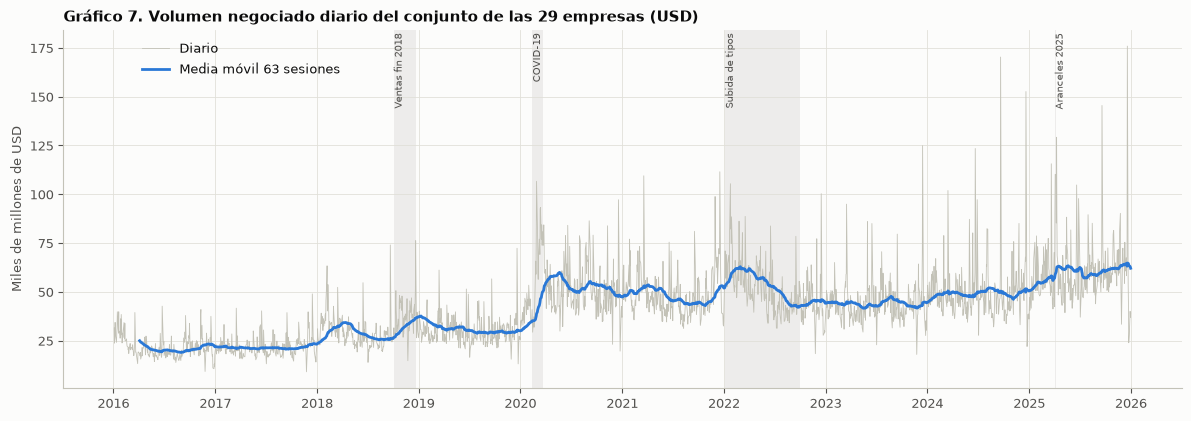

In [48]:
volumen_analisis = volumen.mask(ratio_volumen < 0.2)
if yahoo_empresas is not None:          # si hay Yahoo, se imputa con su volumen en lugar de dejar el hueco
    volumen_analisis = volumen_analisis.fillna(vol_yahoo.where(volumen.notna()))

# Volumen en dólares (precio x acciones): no depende de los splits y es comparable entre empresas
dolares = precios * volumen_analisis
dolares_mercado = dolares.sum(axis=1, min_count=max(1, N - 6)) / 1e9

fig, ax = plt.subplots(figsize=(12, 4.3))
sombrear_episodios(ax, etiquetas=True)
ax.plot(dolares_mercado, color="#c3c2b7", lw=0.6, label="Diario")
ax.plot(dolares_mercado.rolling(VENTANA_LARGA).mean(), color=AZUL, lw=2, label=f"Media móvil {VENTANA_LARGA} sesiones")
ax.set_ylabel("Miles de millones de USD")
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.legend(loc="upper left", bbox_to_anchor=(0.06, 1))
ax.set_title(f"Gráfico 7. Volumen negociado diario del conjunto de las {N} empresas (USD)")
plt.tight_layout()
plt.show()

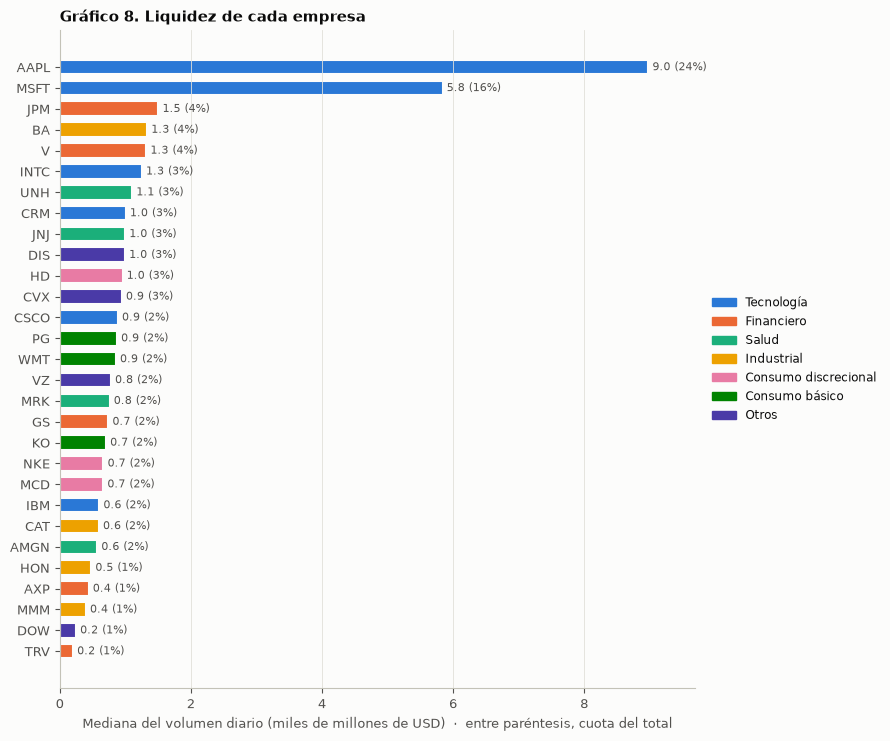

Las 5 empresas más líquidas concentran el 52% del volumen
Correlación entre volumen del mercado y |rentabilidad| del mercado: 0.33


In [49]:
liquidez = (dolares.median() / 1e9).sort_values()
cuota = liquidez / liquidez.sum()

fig, ax = plt.subplots(figsize=(9, 7.5))
barras = ax.barh(liquidez.index, liquidez, color=[color(t) for t in liquidez.index], height=0.7,
                 edgecolor=FONDO, linewidth=1.5)
ax.bar_label(barras, labels=[f"{v:.1f} ({c:.0%})" for v, c in zip(liquidez, cuota)], padding=3,
             fontsize=8, color=TINTA_2)
ax.set_xlabel("Mediana del volumen diario (miles de millones de USD)  ·  entre paréntesis, cuota del total")
ax.grid(axis="y", visible=False)
ax.margins(x=0.08)
leyenda_sectores(ax)
ax.set_title("Gráfico 8. Liquidez de cada empresa")
plt.tight_layout()
plt.show()

print(f"Las 5 empresas más líquidas concentran el {cuota.tail(5).sum():.0%} del volumen")
print(f"Correlación entre volumen del mercado y |rentabilidad| del mercado: "
      f"{dolares_mercado.corr(rent_mercado.abs()):.2f}")

**Qué mirar:**
- Los picos de volumen coinciden con los episodios de caída (gráfico 7): en las crisis se negocia más.
  La correlación positiva entre volumen y |rentabilidad| lo resume en un número.
- La concentración de la liquidez (gráfico 8). Para la cartera, todas estas empresas son muy líquidas, pero
  las de menor volumen tienen más coste de ejecución en operaciones grandes.

# 5. Rentabilidades diarias: medias, colas y días extremos

In [50]:
def estadisticos(r):
    r = r.dropna()
    return pd.Series({
        "media_anual": r.mean() * DIAS_ANIO,
        "volatilidad_anual": r.std() * np.sqrt(DIAS_ANIO),
        "asimetria": stats.skew(r),
        "curtosis_exceso": stats.kurtosis(r),          # 0 para una normal
        "peor_dia": r.min(), "fecha_peor": r.idxmin().date(),
        "mejor_dia": r.max(), "fecha_mejor": r.idxmax().date(),
        "pct_dias_positivos": (r > 0).mean(),
    })


tabla_r = rent_log.apply(estadisticos).T
tabla_r.loc["MERCADO"] = estadisticos(rent_log_mercado)
numericas = tabla_r.columns.drop(["fecha_peor", "fecha_mejor"])
tabla_r[numericas] = tabla_r[numericas].astype(float).round(4)
print(tabla_r.loc[orden_sector + ["MERCADO"]].to_string())

         media_anual  volatilidad_anual  asimetria  curtosis_exceso  peor_dia  fecha_peor  mejor_dia fecha_mejor  pct_dias_positivos
symbol                                                                                                                              
AAPL          0.2341             0.2896    -0.0972           6.7815   -0.1395  2020-03-16     0.1426  2025-04-09              0.5360
CRM           0.1243             0.3503    -0.2415          13.4075   -0.2199  2024-05-30     0.2352  2020-08-26              0.5241
CSCO          0.1073             0.2515    -0.7139          12.2141   -0.1477  2022-05-19     0.1255  2020-03-13              0.5300
IBM           0.0826             0.2497    -0.4370          10.6558   -0.1375  2020-03-12     0.1219  2025-01-30              0.5324
INTC          0.0082             0.4043    -0.6112          16.3151   -0.3019  2024-08-02     0.2052  2025-09-18              0.5101
MSFT          0.2184             0.2675    -0.1561           7.9204  

Jarque-Bera = 50,134 (p-valor 0.0e+00) -> se rechaza la normalidad
Días con |r| > 3 desviaciones: 33 observados frente a 6.8 esperados con una normal


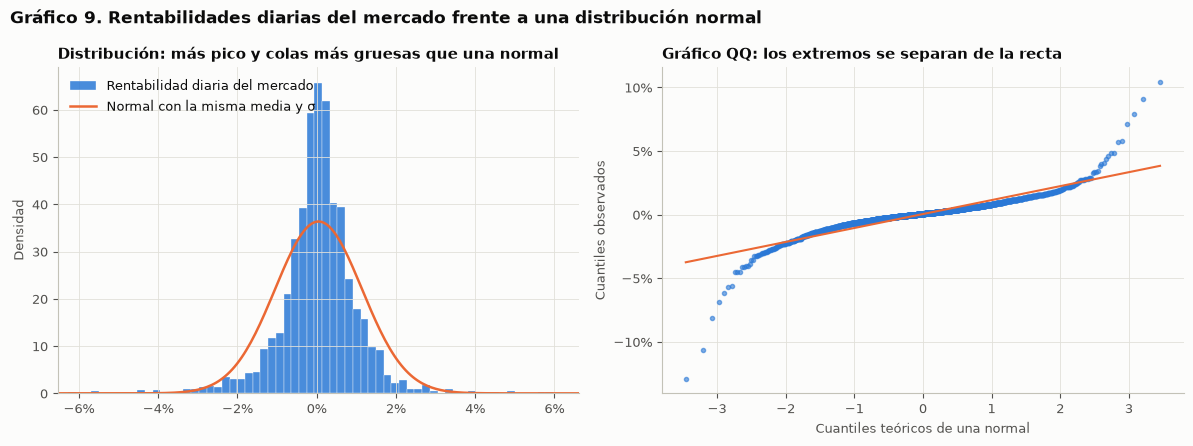

In [51]:
r = rent_log_mercado.dropna()
mu, sigma = r.mean(), r.std()
jb = stats.jarque_bera(r)
print(f"Jarque-Bera = {jb.statistic:,.0f} (p-valor {jb.pvalue:.1e}) -> "
      f"{'se rechaza' if jb.pvalue < 0.05 else 'no se rechaza'} la normalidad")
print(f"Días con |r| > 3 desviaciones: {(np.abs(r - mu) > 3 * sigma).sum()} observados "
      f"frente a {len(r) * 2 * stats.norm.sf(3):.1f} esperados con una normal")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
ax1.hist(r, bins=120, density=True, color=AZUL, alpha=0.85, edgecolor=FONDO, linewidth=0.3,
         label="Rentabilidad diaria del mercado")
x = np.linspace(r.min(), r.max(), 400)
ax1.plot(x, stats.norm.pdf(x, mu, sigma), color=NARANJA, lw=1.8, label="Normal con la misma media y σ")
ax1.set_xlim(mu - 6 * sigma, mu + 6 * sigma)
eje_pct(ax1, "x", 0)
ax1.set_ylabel("Densidad")
ax1.legend(loc="upper left")
ax1.set_title("Distribución: más pico y colas más gruesas que una normal")

(teoricos, observados), _ = stats.probplot(r, dist="norm")
ax2.plot(teoricos, observados, "o", ms=3, color=AZUL, alpha=0.6)
ax2.plot(teoricos, mu + sigma * teoricos, color=NARANJA, lw=1.5)
ax2.set_xlabel("Cuantiles teóricos de una normal")
ax2.set_ylabel("Cuantiles observados")
eje_pct(ax2, "y", 0)
ax2.set_title("Gráfico QQ: los extremos se separan de la recta")
fig.suptitle("Gráfico 9. Rentabilidades diarias del mercado frente a una distribución normal", x=0.01, ha="left")
plt.tight_layout()
plt.show()

In [52]:
extremos = pd.DataFrame({"rentabilidad": rent_mercado,
                         "empresas_en_negativo": (rent < 0).sum(axis=1) / rent.notna().sum(axis=1)})
print("10 peores días del mercado:")
print(extremos.nsmallest(10, "rentabilidad").assign(
    rentabilidad=lambda d: d["rentabilidad"].map("{:+.2%}".format),
    empresas_en_negativo=lambda d: d["empresas_en_negativo"].map("{:.0%}".format)).to_string())
print("\n10 mejores días del mercado:")
print(extremos.nlargest(10, "rentabilidad").assign(
    rentabilidad=lambda d: d["rentabilidad"].map("{:+.2%}".format),
    empresas_en_negativo=lambda d: d["empresas_en_negativo"].map("{:.0%}".format)).to_string())

10 peores días del mercado:
           rentabilidad empresas_en_negativo
date                                        
2020-03-16      -12.09%                 100%
2020-03-12      -10.09%                 100%
2020-03-09       -7.83%                 100%
2020-06-11       -6.62%                 100%
2025-04-04       -6.00%                  97%
2020-03-11       -5.52%                 100%
2020-03-18       -5.48%                  83%
2020-02-27       -4.41%                  97%
2018-02-05       -4.39%                 100%
2020-04-01       -4.38%                  97%

10 mejores días del mercado:
           rentabilidad empresas_en_negativo
date                                        
2020-03-24      +11.00%                   3%
2020-03-13       +9.56%                   0%
2025-04-09       +8.25%                   0%
2020-04-06       +7.35%                   0%
2020-03-26       +5.95%                   3%
2020-03-17       +5.89%                  14%
2018-12-26       +4.99%                   

**Qué mirar:**
- Curtosis en exceso claramente mayor que 0 y un QQ que se curva en los extremos: las caídas grandes son
  mucho más frecuentes de lo que diría una normal. Es la razón para no medir el riesgo solo con σ.
- La asimetría: si es negativa, las caídas fuertes son más grandes que las subidas fuertes.
- Si los peores y los mejores días están muy juntos en el tiempo (normalmente en marzo de 2020): las
  subidas más fuertes llegan en plena crisis.
- En los peores días casi todas las empresas caen a la vez: en ese momento la diversificación ayuda poco
  (se cuantifica en la sección 9).

# 6. Volatilidad: cuánto riesgo hay y cómo cambia en el tiempo

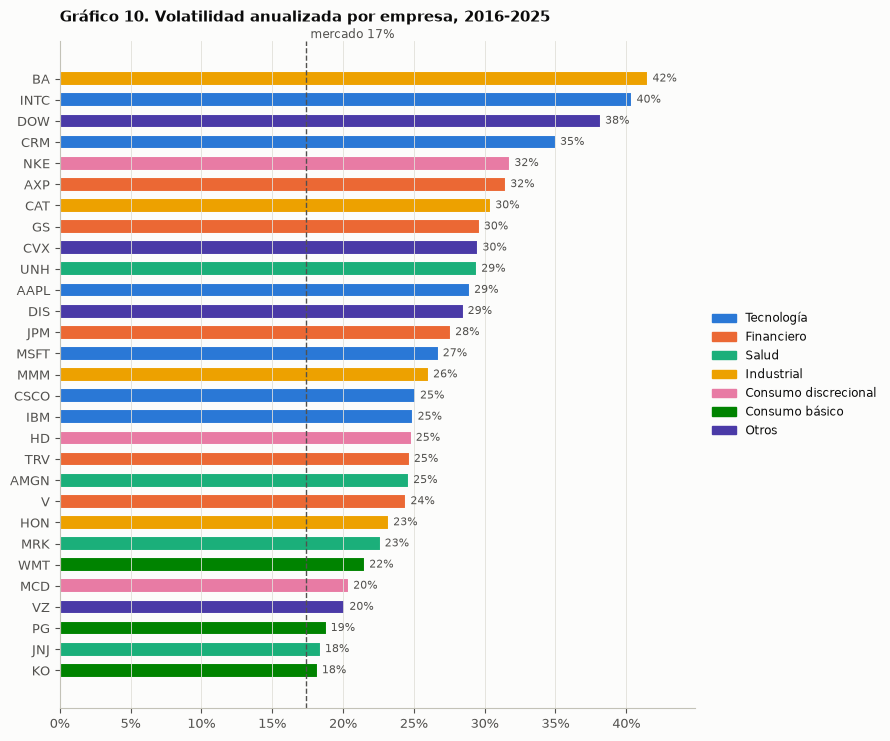

Volatilidad media de las empresas 27.2% frente a la del mercado 17.4%: la diversificación elimina un 36% del riesgo medio


In [53]:
vol_empresas = (rent_log.std() * np.sqrt(DIAS_ANIO)).sort_values()
vol_mercado = rent_log_mercado.std() * np.sqrt(DIAS_ANIO)

fig, ax = plt.subplots(figsize=(9, 7.5))
barras = ax.barh(vol_empresas.index, vol_empresas, color=[color(t) for t in vol_empresas.index],
                 height=0.7, edgecolor=FONDO, linewidth=1.5)
ax.bar_label(barras, labels=[f"{v:.0%}" for v in vol_empresas], padding=3, fontsize=8, color=TINTA_2)
ax.axvline(vol_mercado, color=TINTA_2, lw=1, ls="--")
ax.text(vol_mercado, 1.0, f" mercado {vol_mercado:.0%}", transform=ax.get_xaxis_transform(),
        fontsize=8.5, color=TINTA_2, va="bottom")
eje_pct(ax, "x")
ax.grid(axis="y", visible=False)
ax.margins(x=0.08)
leyenda_sectores(ax)
ax.set_title("Gráfico 10. Volatilidad anualizada por empresa, 2016-2025", pad=14)
plt.tight_layout()
plt.show()

print(f"Volatilidad media de las empresas {vol_empresas.mean():.1%} frente a la del mercado {vol_mercado:.1%}: "
      f"la diversificación elimina un {1 - vol_mercado / vol_empresas.mean():.0%} del riesgo medio")

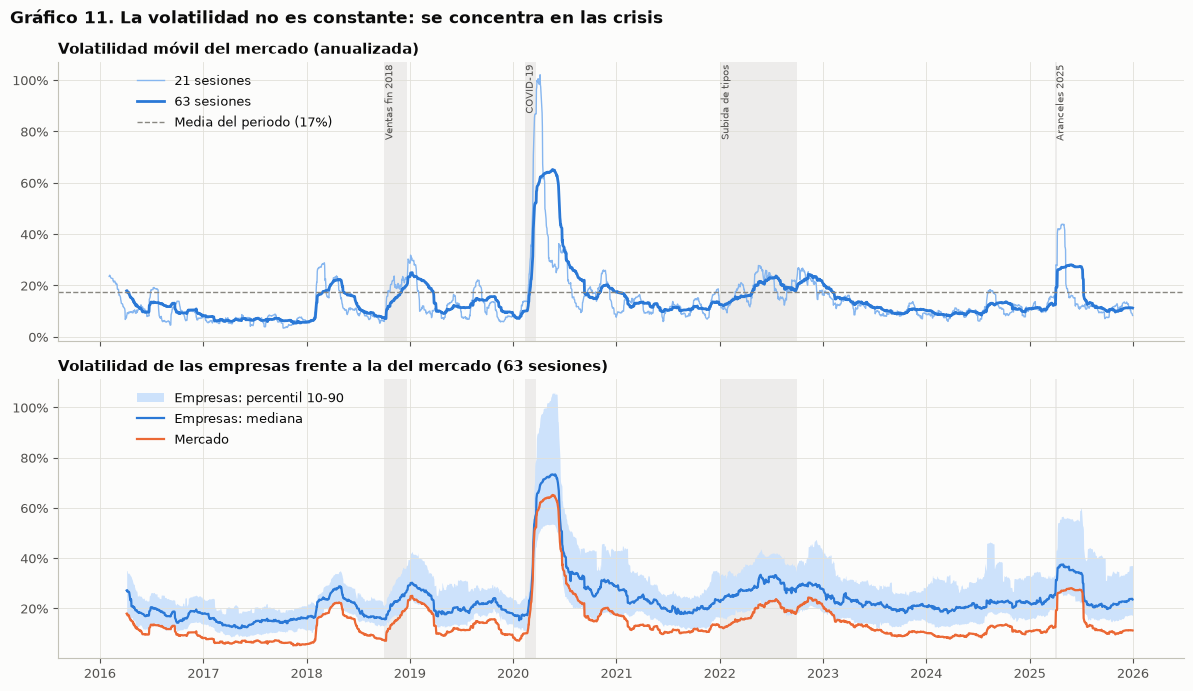

Volatilidad del mercado por año: {2016: 12.8, 2017: 6.4, 2018: 17.3, 2019: 12.1, 2020: 36.2, 2021: 12.1, 2022: 20.0, 2023: 11.5, 2024: 10.7, 2025: 16.8}


In [54]:
vol_corta = rent_log_mercado.rolling(VENTANA_CORTA).std() * np.sqrt(DIAS_ANIO)
vol_larga = rent_log_mercado.rolling(VENTANA_LARGA).std() * np.sqrt(DIAS_ANIO)
vol_movil_empresas = rent_log.rolling(VENTANA_LARGA, min_periods=VENTANA_LARGA).std() * np.sqrt(DIAS_ANIO)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
sombrear_episodios(ax1, etiquetas=True)
ax1.plot(vol_corta, color="#86b6ef", lw=1, label=f"{VENTANA_CORTA} sesiones")
ax1.plot(vol_larga, color=AZUL, lw=2, label=f"{VENTANA_LARGA} sesiones")
ax1.axhline(vol_mercado, color=GRIS, lw=1, ls="--", label=f"Media del periodo ({vol_mercado:.0%})")
eje_pct(ax1)
ax1.legend(loc="upper left", bbox_to_anchor=(0.06, 1))
ax1.set_title("Volatilidad móvil del mercado (anualizada)")

sombrear_episodios(ax2)
ax2.fill_between(vol_movil_empresas.index, vol_movil_empresas.quantile(0.1, axis=1),
                 vol_movil_empresas.quantile(0.9, axis=1), color="#cde2fb", lw=0,
                 label="Empresas: percentil 10-90")
ax2.plot(vol_movil_empresas.median(axis=1), color=AZUL, lw=1.6, label="Empresas: mediana")
ax2.plot(vol_larga, color=NARANJA, lw=1.6, label="Mercado")
eje_pct(ax2)
ax2.legend(loc="upper left", bbox_to_anchor=(0.06, 1))
ax2.set_title(f"Volatilidad de las empresas frente a la del mercado ({VENTANA_LARGA} sesiones)")
ax2.xaxis.set_major_locator(mdates.YearLocator())
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fig.suptitle("Gráfico 11. La volatilidad no es constante: se concentra en las crisis", x=0.01, ha="left")
plt.tight_layout()
plt.show()

vol_por_anio = rent_log_mercado.groupby(rent_log_mercado.index.year).std() * np.sqrt(DIAS_ANIO)
print("Volatilidad del mercado por año:", (vol_por_anio * 100).round(1).to_dict())

**Qué mirar:**
- El mercado es menos volátil que casi todas sus empresas (gráfico 10): es el efecto de la diversificación.
- La volatilidad viene por rachas (gráfico 11): periodos tranquilos largos y picos muy altos en las crisis.
  Una volatilidad media del periodo esconde regímenes muy distintos.
- En los picos, la banda de las empresas y la línea del mercado se acercan: cuando todas se mueven juntas,
  la diversificación protege menos.

# 7. Riesgo frente a rentabilidad: qué empresas compensan su riesgo

In [55]:
# Tasa libre de riesgo: media de la letra del Tesoro a 13 semanas (^IRX, en %) o el valor por defecto
yahoo_irx = descargar_yahoo(["^IRX"], ["Close"])
if yahoo_irx is not None and yahoo_irx["Close"]["^IRX"].notna().any():
    TASA_LIBRE = yahoo_irx["Close"]["^IRX"].mean() / 100
    print(f"Tasa libre de riesgo (media de ^IRX 2016-2025): {TASA_LIBRE:.2%}")
else:
    TASA_LIBRE = TASA_LIBRE_DEFECTO
    print(f"Tasa libre de riesgo por defecto: {TASA_LIBRE:.2%}")


def ratios(r_simple):
    r_simple = r_simple.dropna()
    media = r_simple.mean() * DIAS_ANIO
    vol = r_simple.std() * np.sqrt(DIAS_ANIO)
    bajista = np.sqrt((np.minimum(r_simple, 0) ** 2).mean()) * np.sqrt(DIAS_ANIO)
    return pd.Series({"rentabilidad_media": media, "volatilidad": vol,
                      "sharpe": (media - TASA_LIBRE) / vol, "sortino": (media - TASA_LIBRE) / bajista})


riesgo = rent.apply(ratios).T
riesgo["cagr"] = cagr_empresas
riesgo.loc["MERCADO"] = ratios(rent_mercado)
riesgo.loc["MERCADO", "cagr"] = cagr_mercado
print(riesgo.sort_values("sharpe", ascending=False).round(3).to_string())

Tasa libre de riesgo (media de ^IRX 2016-2025): 2.16%
         rentabilidad_media  volatilidad  sharpe  sortino   cagr
symbol                                                          
AAPL                  0.276        0.290   0.878    1.295  0.263
MSFT                  0.254        0.268   0.869    1.284  0.244
WMT                   0.193        0.216   0.794    1.191  0.185
CAT                   0.260        0.304   0.784    1.147  0.238
V                     0.184        0.245   0.662    0.959  0.166
JPM                   0.201        0.277   0.648    0.957  0.176
MERCADO               0.131        0.174   0.631    0.894  0.123
AXP                   0.220        0.317   0.626    0.946  0.185
GS                    0.205        0.297   0.617    0.906  0.174
CSCO                  0.139        0.250   0.468    0.656  0.113
CRM                   0.186        0.350   0.468    0.677  0.132
MCD                   0.117        0.204   0.465    0.676  0.100
TRV                   0.128        0

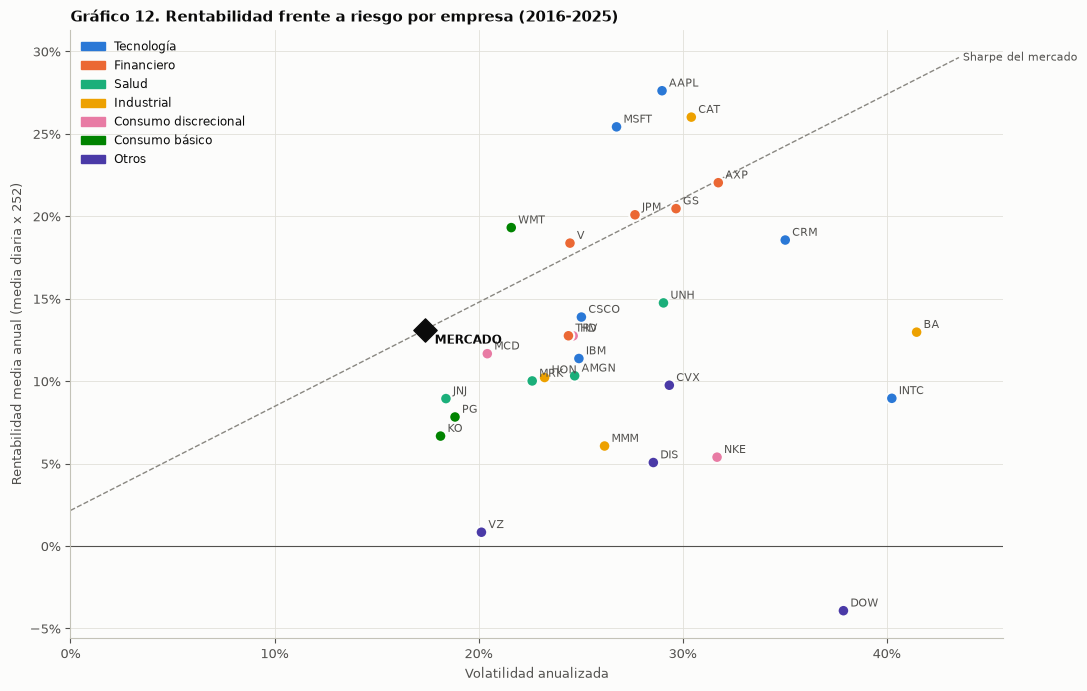

In [56]:
fig, ax = plt.subplots(figsize=(11, 7))
puntos = riesgo.drop("MERCADO")
ax.scatter(puntos["volatilidad"], puntos["rentabilidad_media"], s=70, c=[color(t) for t in puntos.index],
           edgecolor=FONDO, linewidth=1.5, zorder=3)
for ticker, fila in puntos.iterrows():
    ax.annotate(ticker, (fila["volatilidad"], fila["rentabilidad_media"]), xytext=(5, 3), textcoords="offset points",
                fontsize=8, color=TINTA_2)
mercado = riesgo.loc["MERCADO"]
ax.scatter(mercado["volatilidad"], mercado["rentabilidad_media"], s=140, marker="D", color=TINTA, zorder=4)
ax.annotate("MERCADO", (mercado["volatilidad"], mercado["rentabilidad_media"]), xytext=(7, -10),
            textcoords="offset points", fontsize=8.5, fontweight="bold", color=TINTA)

# Línea con el Sharpe del mercado (mismo eje y que el Sharpe: rentabilidad media): por encima, más rentabilidad por unidad de riesgo que el mercado
x = np.linspace(0, puntos["volatilidad"].max() * 1.05, 50)
ax.plot(x, TASA_LIBRE + mercado["sharpe"] * x, color=GRIS, lw=1, ls="--")
ax.text(x[-1], TASA_LIBRE + mercado["sharpe"] * x[-1], " Sharpe del mercado", fontsize=8, color=TINTA_2,
        va="center")
ax.axhline(0, color=TINTA_2, lw=0.8)
ax.set_xlim(left=0)
eje_pct(ax, "x")
eje_pct(ax, "y")
ax.set_xlabel("Volatilidad anualizada")
ax.set_ylabel("Rentabilidad media anual (media diaria x 252)")
leyenda_sectores(ax, loc="upper left", bbox_to_anchor=None)
ax.set_title("Gráfico 12. Rentabilidad frente a riesgo por empresa (2016-2025)")
plt.tight_layout()
plt.show()

**Qué mirar:**
- Las empresas por encima de la línea discontinua han dado más rentabilidad por unidad de riesgo que el
  mercado; las de abajo, menos. Son una primera lista de candidatas (y de descartes) para la cartera.
- El mercado debería quedar a la izquierda de casi todas: con menos riesgo que la media de las empresas
  obtiene una rentabilidad parecida. Es el argumento a favor de diversificar.
- Sortino frente a Sharpe: si una empresa mejora mucho con Sortino, su volatilidad viene sobre todo de
  subidas, no de caídas.
- Recuerda que son resultados pasados de un único periodo (2016-2025) y sin dividendos.

# 8. Drawdowns: cuánto se puede llegar a perder y cuánto se tarda en recuperar

Caídas del mercado de más del 10 %:
    maximo     minimo recuperacion  caida  sesiones_hasta_minimo  sesiones_total
2020-02-12 2020-03-23   2020-08-28 -34.2%                     27             138
2022-01-04 2022-09-30   2023-12-01 -22.2%                    186             480
2025-02-19 2025-04-08   2025-07-03 -16.1%                     34              93
2018-10-03 2018-12-24   2019-03-15 -16.0%                     56             111
2018-01-26 2018-03-23   2018-08-21 -10.5%                     39             143


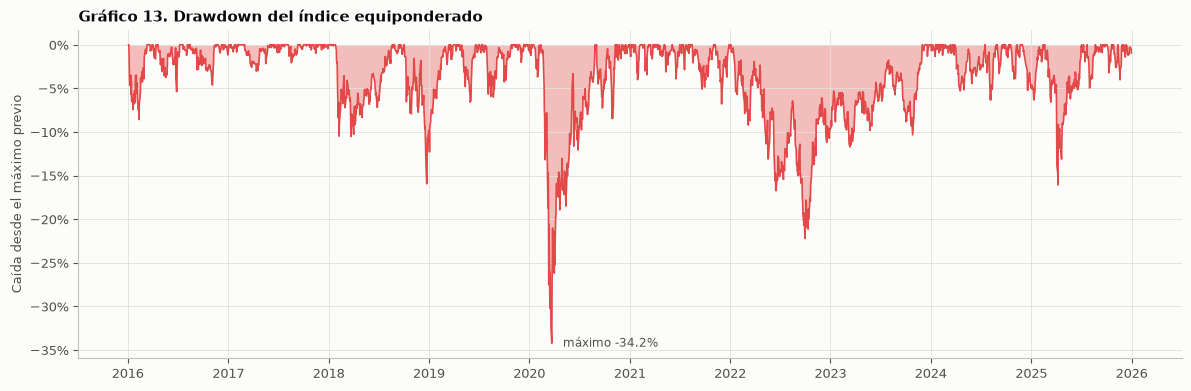

In [57]:
def drawdown(nivel):
    nivel = nivel.dropna()
    return nivel / nivel.cummax() - 1


def episodios_drawdown(nivel, umbral=-0.10):
    """Caídas desde un máximo de más del umbral: fecha del máximo, del mínimo y de la recuperación."""
    dd = drawdown(nivel)
    grupo = (dd == 0).cumsum()
    filas = []
    for _, tramo in dd.groupby(grupo):
        if tramo.min() > umbral:
            continue
        posicion = dd.index.get_loc(tramo.index[-1])
        recuperacion = dd.index[posicion + 1] if posicion + 1 < len(dd) else pd.NaT
        filas.append({"maximo": tramo.index[0].date(), "minimo": tramo.idxmin().date(),
                      "recuperacion": recuperacion.date() if pd.notna(recuperacion) else "sin recuperar",
                      "caida": tramo.min(), "sesiones_hasta_minimo": dd.index.get_loc(tramo.idxmin()) - dd.index.get_loc(tramo.index[0]),
                      "sesiones_total": len(tramo)})
    return pd.DataFrame(filas).sort_values("caida")


dd_mercado = drawdown(indice_ew)
print("Caídas del mercado de más del 10 %:")
print(episodios_drawdown(indice_ew).assign(caida=lambda d: d["caida"].map("{:.1%}".format)).to_string(index=False))

fig, ax = plt.subplots(figsize=(12, 4))
ax.fill_between(dd_mercado.index, dd_mercado, 0, color=ROJO, alpha=0.35, lw=0)
ax.plot(dd_mercado, color=ROJO, lw=1.2)
ax.annotate(f"máximo {dd_mercado.min():.1%}", (dd_mercado.idxmin(), dd_mercado.min()), xytext=(8, 0),
            textcoords="offset points", fontsize=8.5, color=TINTA_2, va="center")
eje_pct(ax)
ax.set_ylabel("Caída desde el máximo previo")
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.set_title("Gráfico 13. Drawdown del índice equiponderado")
plt.tight_layout()
plt.show()

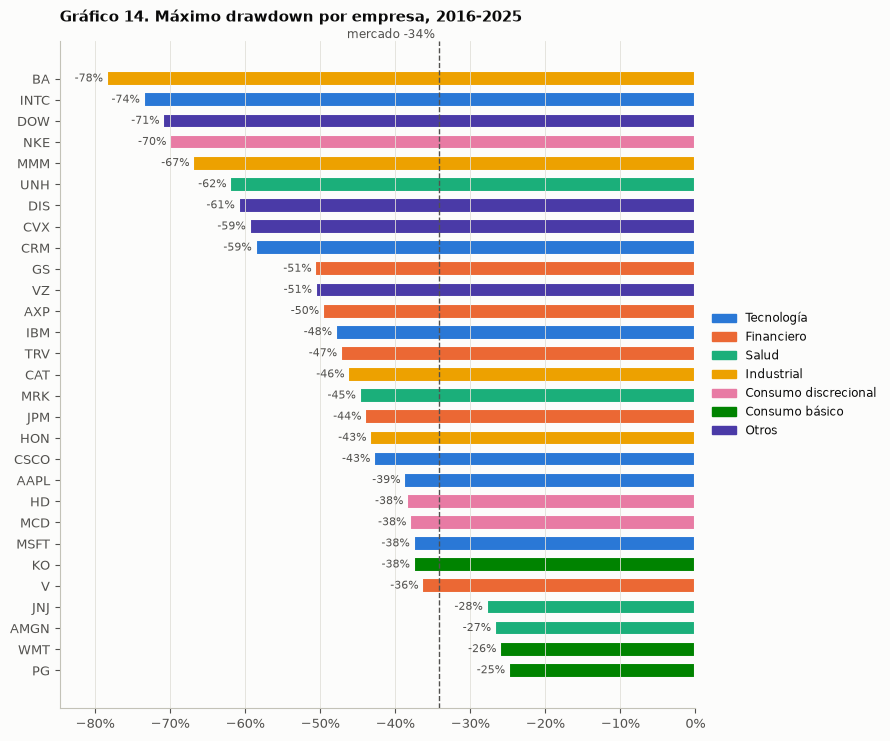

Empresas que a final de 2025 siguen más de un 20 % por debajo de su máximo:
        max_drawdown fecha_minimo  drawdown_final
symbol                                           
PG            -0.249   2018-05-02          -0.203
HD            -0.384   2020-03-20          -0.202
MRK           -0.447   2025-05-14          -0.208
VZ            -0.506   2023-10-13          -0.344
CRM           -0.586   2022-12-16          -0.280
DIS           -0.609   2023-10-04          -0.439
UNH           -0.620   2025-08-01          -0.472
MMM           -0.669   2023-10-23          -0.260
NKE           -0.700   2025-04-08          -0.641
DOW           -0.709   2025-10-10          -0.671
INTC          -0.735   2025-04-08          -0.461
BA            -0.784   2020-03-20          -0.507


In [58]:
dd_empresas = pd.DataFrame({
    "max_drawdown": precios.apply(lambda s: drawdown(s).min()),
    "fecha_minimo": precios.apply(lambda s: drawdown(s).idxmin().date()),
    "drawdown_final": precios.apply(lambda s: drawdown(s).iloc[-1]),
}).sort_values("max_drawdown", ascending=False)

fig, ax = plt.subplots(figsize=(9, 7.5))
barras = ax.barh(dd_empresas.index, dd_empresas["max_drawdown"],
                 color=[color(t) for t in dd_empresas.index], height=0.7, edgecolor=FONDO, linewidth=1.5)
ax.bar_label(barras, labels=[f"{v:.0%}" for v in dd_empresas["max_drawdown"]], padding=3, fontsize=8,
             color=TINTA_2)
ax.axvline(dd_mercado.min(), color=TINTA_2, lw=1, ls="--")
ax.text(dd_mercado.min(), 1.0, f"mercado {dd_mercado.min():.0%} ", transform=ax.get_xaxis_transform(),
        fontsize=8.5, color=TINTA_2, va="bottom", ha="right")
eje_pct(ax, "x")
ax.grid(axis="y", visible=False)
ax.margins(x=0.08)
leyenda_sectores(ax)
ax.set_title("Gráfico 14. Máximo drawdown por empresa, 2016-2025", pad=14)
plt.tight_layout()
plt.show()

print("Empresas que a final de 2025 siguen más de un 20 % por debajo de su máximo:")
print(dd_empresas[dd_empresas["drawdown_final"] < -0.2].round(3).to_string())

**Qué mirar:**
- La profundidad y, sobre todo, la duración de las caídas del mercado: cuánto tarda en volver al máximo
  previo después de cada crisis.
- Empresas con un máximo drawdown muy superior al del mercado (gráfico 14) y empresas que todavía no se han
  recuperado: son las que más daño hacen en una cartera concentrada.
- La volatilidad (sección 6) y el drawdown no ordenan igual a las empresas: una empresa puede tener una
  volatilidad moderada y aun así una caída muy profunda y persistente.

# 9. Correlaciones: cuánto se mueven juntas y si cambia en las crisis

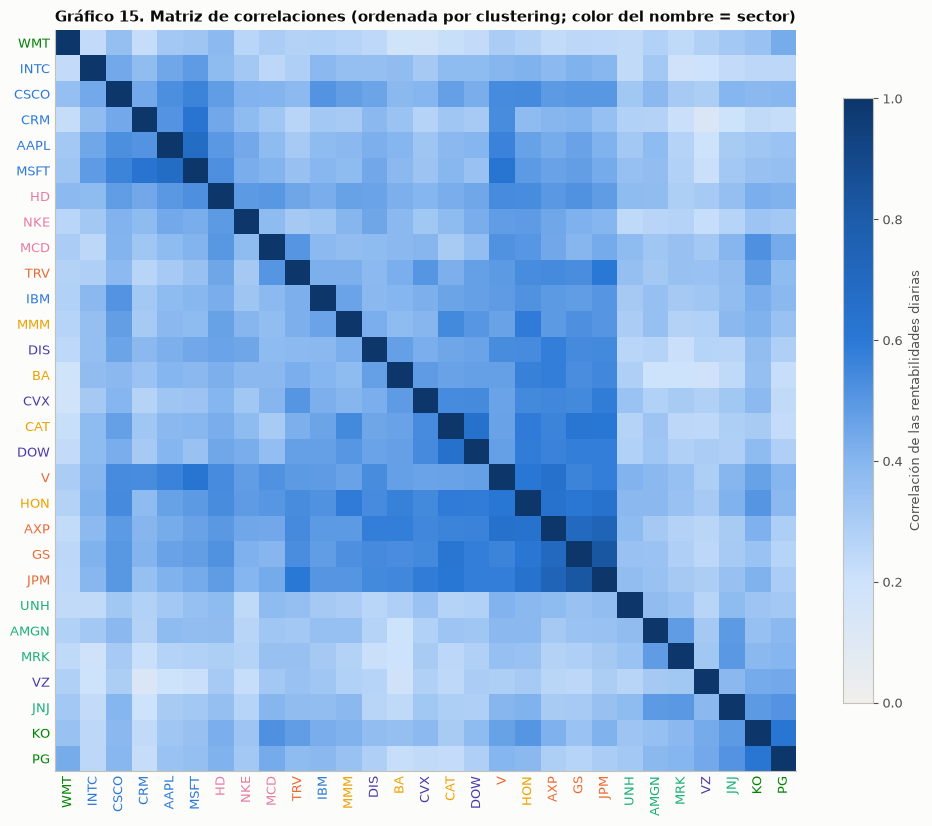

Correlación media entre empresas: 0.39
Pares más correlacionados: {('GS', 'JPM'): 0.82, ('AXP', 'JPM'): 0.74, ('AXP', 'GS'): 0.7, ('AAPL', 'MSFT'): 0.67, ('AXP', 'V'): 0.65}
Pares menos correlacionados: {('CRM', 'VZ'): 0.13, ('CVX', 'WMT'): 0.18, ('BA', 'WMT'): 0.19, ('BA', 'VZ'): 0.19, ('INTC', 'MRK'): 0.19}


In [59]:
correlacion = rent_log.corr()

# Orden por clustering jerárquico: las empresas que se mueven parecido quedan juntas
distancia = np.sqrt(0.5 * (1 - correlacion.clip(-1, 1).to_numpy()))
np.fill_diagonal(distancia, 0)
orden_cluster = correlacion.index[leaves_list(linkage(squareform(distancia, checks=False), "average"))]
matriz = correlacion.loc[orden_cluster, orden_cluster]

fig, ax = plt.subplots(figsize=(10, 9))
imagen = ax.imshow(matriz.values, cmap=SECUENCIAL, vmin=0, vmax=1)
ax.set_xticks(range(len(matriz)), matriz.columns, rotation=90)
ax.set_yticks(range(len(matriz)), matriz.index)
for etiqueta in ax.get_xticklabels() + ax.get_yticklabels():
    etiqueta.set_color(color(etiqueta.get_text()))
ax.grid(False)
ax.tick_params(length=0)
fig.colorbar(imagen, ax=ax, shrink=0.7, label="Correlación de las rentabilidades diarias")
ax.set_title("Gráfico 15. Matriz de correlaciones (ordenada por clustering; color del nombre = sector)")
plt.tight_layout()
plt.show()

fuera_diagonal = correlacion.where(~np.eye(len(correlacion), dtype=bool))
print(f"Correlación media entre empresas: {np.nanmean(fuera_diagonal.values):.2f}")
pares = fuera_diagonal.stack()
pares = pares[pares.index.get_level_values(0) < pares.index.get_level_values(1)]
print("Pares más correlacionados:", pares.nlargest(5).round(2).to_dict())
print("Pares menos correlacionados:", pares.nsmallest(5).round(2).to_dict())

In [60]:
# Correlación media dentro de cada sector frente a la correlación con el resto
filas = []
for sector in COLOR_SECTOR:
    dentro = [t for t in empresas if SECTOR[t] == sector]
    if not dentro:
        continue
    fuera = [t for t in empresas if SECTOR[t] != sector]
    intra = fuera_diagonal.loc[dentro, dentro].stack().mean() if len(dentro) > 1 else np.nan
    filas.append({"sector": sector, "empresas": len(dentro), "corr_dentro_sector": intra,
                  "corr_con_otros_sectores": correlacion.loc[dentro, fuera].stack().mean()})
print(pd.DataFrame(filas).round(2).to_string(index=False))

              sector  empresas  corr_dentro_sector  corr_con_otros_sectores
          Tecnología         6                0.47                     0.37
          Financiero         5                0.62                     0.43
               Salud         4                0.43                     0.32
          Industrial         4                0.52                     0.41
Consumo discrecional         3                0.45                     0.39
      Consumo básico         3                0.46                     0.33
               Otros         4                0.38                     0.37


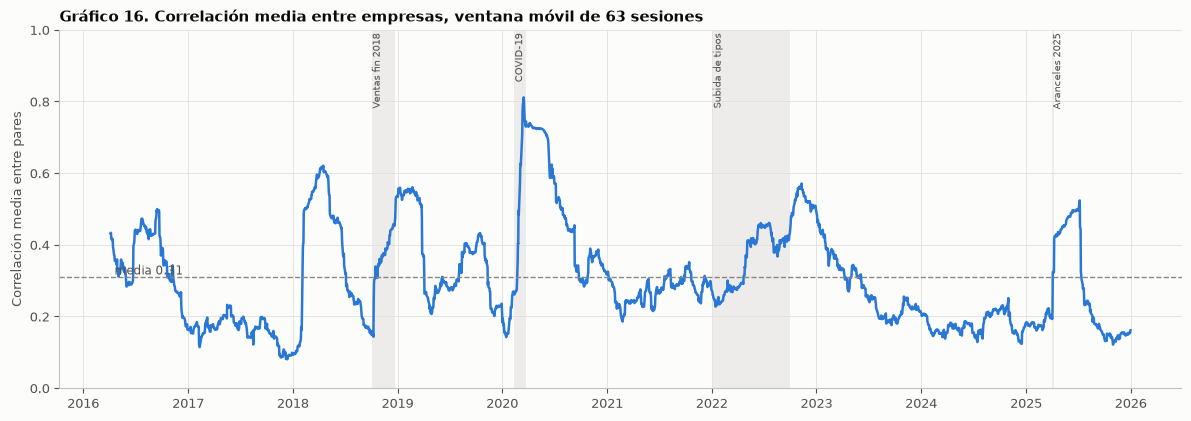

Correlación entre la correlación media y la volatilidad del mercado: 0.82


In [61]:
def correlacion_media_movil(r, ventana):
    """Media de las correlaciones entre pares en cada ventana (solo empresas con la ventana completa)."""
    valores, datos = {}, r.values
    for fin in range(ventana, len(r) + 1):
        bloque = datos[fin - ventana:fin]
        completas = ~np.isnan(bloque).any(axis=0)
        c = np.corrcoef(bloque[:, completas], rowvar=False)
        n = c.shape[0]
        valores[r.index[fin - 1]] = (c.sum() - n) / (n * (n - 1))
    return pd.Series(valores)


corr_movil = correlacion_media_movil(rent_log.iloc[1:], VENTANA_LARGA)

fig, ax = plt.subplots(figsize=(12, 4.3))
sombrear_episodios(ax, etiquetas=True)
ax.plot(corr_movil, color=AZUL, lw=1.8)
ax.axhline(corr_movil.mean(), color=GRIS, lw=1, ls="--")
ax.text(corr_movil.index[0], corr_movil.mean(), f" media {corr_movil.mean():.2f}", fontsize=8.5,
        color=TINTA_2, va="bottom")
ax.set_ylim(0, 1)
ax.set_ylabel("Correlación media entre pares")
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.set_title(f"Gráfico 16. Correlación media entre empresas, ventana móvil de {VENTANA_LARGA} sesiones")
plt.tight_layout()
plt.show()

print(f"Correlación entre la correlación media y la volatilidad del mercado: {corr_movil.corr(vol_larga):.2f}")

**Qué mirar:**
- Bloques en la matriz (gráfico 15): si el clustering agrupa por sector, el sector explica buena parte del
  co-movimiento. Para diversificar la cartera conviene mezclar bloques poco correlacionados.
- Que la correlación dentro de cada sector sea mayor que con los demás.
- El gráfico 16 es el más importante de esta sección: si la correlación sube en las crisis (y está
  correlacionada con la volatilidad), la diversificación funciona peor justo cuando más falta hace.

# 10. Beta frente al mercado: sensibilidad de cada empresa

         beta  alfa_anual     r2  beta_dji
symbol                                    
VZ      0.519      -0.060  0.200     0.472
WMT     0.552       0.121  0.197     0.532
JNJ     0.581       0.013  0.301     0.556
PG      0.590       0.001  0.295     0.554
MRK     0.634       0.017  0.237     0.588
KO      0.639      -0.017  0.374     0.597
MCD     0.729       0.021  0.384     0.718
AMGN    0.782       0.001  0.302     0.741
UNH     0.894       0.030  0.286     0.944
TRV     0.919       0.007  0.428     0.896
IBM     0.944      -0.010  0.433     0.913
MMM     1.001      -0.071  0.441     0.970
HD      1.003      -0.004  0.500     1.002
CSCO    1.023       0.005  0.504     0.978
HON     1.063      -0.037  0.631     1.031
MSFT    1.067       0.114  0.479     1.067
V       1.090       0.041  0.599     1.069
DIS     1.096      -0.093  0.444     1.048
CVX     1.109      -0.048  0.431     1.076
AAPL    1.111       0.130  0.444     1.103
NKE     1.117      -0.093  0.375     1.046
CRM     1.1

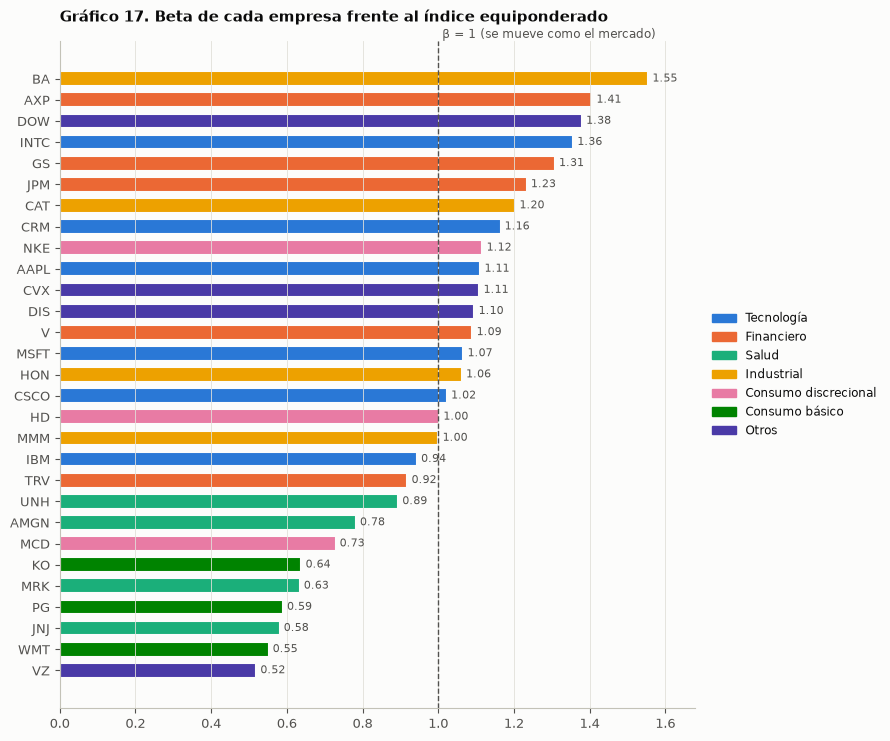

In [62]:
def beta_frente_a(r_empresa, r_referencia):
    datos = pd.concat([r_empresa, r_referencia], axis=1).dropna()
    y, x = datos.iloc[:, 0], datos.iloc[:, 1]
    beta = y.cov(x) / x.var()
    return pd.Series({"beta": beta, "alfa_anual": (y.mean() - beta * x.mean()) * DIAS_ANIO,
                      "r2": y.corr(x) ** 2})


betas = rent.apply(lambda s: beta_frente_a(s, rent_mercado)).T
if dji is not None:
    rent_dji = dji.pct_change().dropna()
    betas["beta_dji"] = rent.apply(lambda s: beta_frente_a(s, rent_dji)["beta"])
betas = betas.sort_values("beta")
print(betas.round(3).to_string())
print(f"\nRiesgo sistemático medio (R²): {betas['r2'].mean():.0%}. "
      f"El resto ({1 - betas['r2'].mean():.0%}) es específico de cada empresa y se puede diversificar.")

fig, ax = plt.subplots(figsize=(9, 7.5))
barras = ax.barh(betas.index, betas["beta"], color=[color(t) for t in betas.index], height=0.7,
                 edgecolor=FONDO, linewidth=1.5)
ax.bar_label(barras, labels=[f"{v:.2f}" for v in betas["beta"]], padding=3, fontsize=8, color=TINTA_2)
ax.axvline(1, color=TINTA_2, lw=1, ls="--")
ax.text(1, 1.0, " β = 1 (se mueve como el mercado)", transform=ax.get_xaxis_transform(), fontsize=8.5,
        color=TINTA_2, va="bottom")
ax.grid(axis="y", visible=False)
ax.margins(x=0.08)
leyenda_sectores(ax)
ax.set_title("Gráfico 17. Beta de cada empresa frente al índice equiponderado", pad=14)
plt.tight_layout()
plt.show()

**Qué mirar:**
- Empresas defensivas (β < 1, normalmente consumo básico y salud) frente a cíclicas (β > 1, normalmente
  financiero, industrial y parte de tecnología). La mezcla de ambas decide la beta de la cartera.
- El R²: qué parte del riesgo de cada empresa es de mercado (no diversificable) y qué parte es propia.
- Nota: el índice equiponderado incluye a cada empresa con un peso de 1/N, lo que sube un poco su beta y su
  R². Si se pudo descargar el `^DJI`, la columna `beta_dji` permite comparar.

# 11. Hechos estilizados y PCA: memoria de la volatilidad y factores del mercado

Ljung-Box (10 retardos) sobre r: Q = 304.6, p-valor = 1.7e-59
Ljung-Box (10 retardos) sobre |r|: Q = 3,370.8, p-valor = 0.0e+00


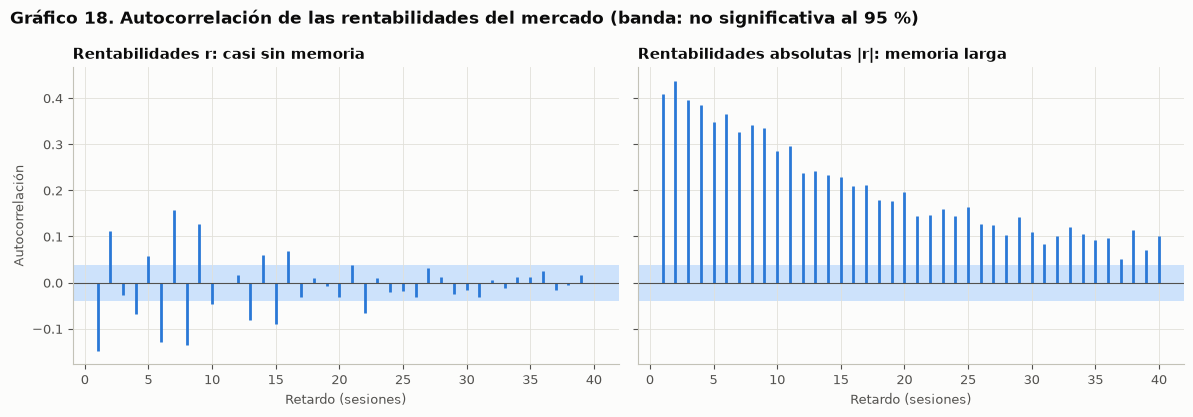

In [63]:
def autocorrelaciones(x, retardos):
    x = np.asarray(x) - np.mean(x)
    denominador = (x ** 2).sum()
    return np.array([(x[k:] * x[:-k]).sum() / denominador for k in range(1, retardos + 1)])


def ljung_box(acf, n):
    q = n * (n + 2) * np.sum(acf ** 2 / (n - np.arange(1, len(acf) + 1)))
    return q, stats.chi2.sf(q, len(acf))


RETARDOS = 40
r = rent_log_mercado.dropna()
acf_r = autocorrelaciones(r, RETARDOS)
acf_abs = autocorrelaciones(r.abs(), RETARDOS)
banda = 1.96 / np.sqrt(len(r))
for nombre, valores in [("r", acf_r), ("|r|", acf_abs)]:
    q, p = ljung_box(valores[:10], len(r))
    print(f"Ljung-Box (10 retardos) sobre {nombre}: Q = {q:,.1f}, p-valor = {p:.1e}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, valores, titulo in [(ax1, acf_r, "Rentabilidades r: casi sin memoria"),
                            (ax2, acf_abs, "Rentabilidades absolutas |r|: memoria larga")]:
    ax.axhspan(-banda, banda, color="#cde2fb", lw=0)
    ax.vlines(range(1, RETARDOS + 1), 0, valores, color=AZUL, lw=2)
    ax.axhline(0, color=TINTA_2, lw=0.8)
    ax.set_xlabel("Retardo (sesiones)")
    ax.set_title(titulo)
ax1.set_ylabel("Autocorrelación")
fig.suptitle("Gráfico 18. Autocorrelación de las rentabilidades del mercado (banda: no significativa al 95 %)",
             x=0.01, ha="left")
plt.tight_layout()
plt.show()

Muestra común: 2019-03-21 a 2025-12-31 (1706 sesiones)
Varianza explicada por los 5 primeros componentes: [42.9, 7.4, 5.5, 3.5, 3.2]


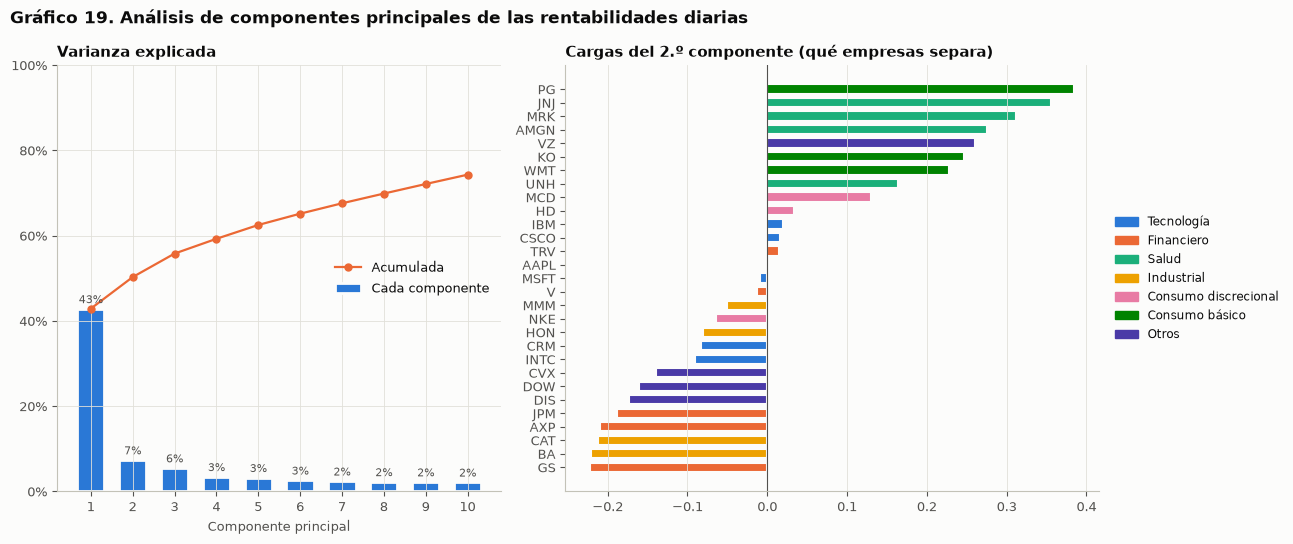

Cargas del 1.er componente (todas del mismo signo = factor mercado):
{'WMT': 0.13, 'VZ': 0.135, 'MRK': 0.137, 'UNH': 0.144, 'AMGN': 0.152, 'INTC': 0.152, 'CRM': 0.155, 'JNJ': 0.16, 'PG': 0.166, 'NKE': 0.175, 'BA': 0.181, 'MMM': 0.186, 'CVX': 0.189, 'AAPL': 0.19, 'MSFT': 0.19, 'KO': 0.19, 'DIS': 0.191, 'IBM': 0.192, 'TRV': 0.192, 'CAT': 0.194, 'MCD': 0.194, 'DOW': 0.195, 'CSCO': 0.2, 'HD': 0.205, 'GS': 0.223, 'V': 0.224, 'JPM': 0.224, 'AXP': 0.226, 'HON': 0.229}


In [64]:
# PCA sobre la matriz de correlaciones. Muestra común: desde que cotiza DOW (todas las empresas con datos)
cobertura = rent_log.notna().mean()
muestra = rent_log.loc[:, cobertura >= 0.5].dropna()      # empresas con al menos la mitad del historial
if (cobertura < 0.5).any():
    print("Fuera del PCA por historial corto:", list(cobertura[cobertura < 0.5].index))
print(f"Muestra común: {muestra.index[0].date()} a {muestra.index[-1].date()} ({len(muestra)} sesiones)")
autovalores, autovectores = np.linalg.eigh(np.corrcoef(muestra.values, rowvar=False))
orden = np.argsort(autovalores)[::-1]
autovalores, autovectores = autovalores[orden], autovectores[:, orden]
explicada = autovalores / autovalores.sum()
cargas = pd.DataFrame(autovectores[:, :3], index=muestra.columns, columns=["PC1", "PC2", "PC3"])
cargas = cargas * np.sign(cargas.mean())          # signo arbitrario: se orienta para que la media sea positiva
print("Varianza explicada por los 5 primeros componentes:", (explicada[:5] * 100).round(1).tolist())

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.5), gridspec_kw={"width_ratios": [1, 1.2]})
k = 10
ax1.bar(range(1, k + 1), explicada[:k], color=AZUL, width=0.65, edgecolor=FONDO, linewidth=2,
        label="Cada componente")
ax1.plot(range(1, k + 1), np.cumsum(explicada[:k]), color=NARANJA, marker="o", ms=5, lw=1.6,
         label="Acumulada")
ax1.bar_label(ax1.containers[0], labels=[f"{v:.0%}" for v in explicada[:k]], padding=2, fontsize=8,
              color=TINTA_2)
eje_pct(ax1)
ax1.set_ylim(0, 1)
ax1.set_xticks(range(1, k + 1))
ax1.set_xlabel("Componente principal")
ax1.legend(loc="center right")
ax1.set_title("Varianza explicada")

pc2 = cargas["PC2"].sort_values()
ax2.barh(pc2.index, pc2, color=[color(t) for t in pc2.index], height=0.7, edgecolor=FONDO, linewidth=1.5)
ax2.axvline(0, color=TINTA_2, lw=0.8)
ax2.grid(axis="y", visible=False)
leyenda_sectores(ax2)
ax2.set_title("Cargas del 2.º componente (qué empresas separa)")
fig.suptitle("Gráfico 19. Análisis de componentes principales de las rentabilidades diarias", x=0.01, ha="left")
plt.tight_layout()
plt.show()

print("Cargas del 1.er componente (todas del mismo signo = factor mercado):")
print(cargas["PC1"].sort_values().round(3).to_dict())

**Qué mirar:**
- **Gráfico 18:** las rentabilidades casi no tienen autocorrelación (lo de ayer apenas predice lo de hoy),
  pero las rentabilidades absolutas sí, y durante muchas sesiones: la volatilidad tiene memoria (los
  clústeres del gráfico 11). Justifica usar modelos tipo GARCH si después se quiere modelizar el riesgo.
- **Gráfico 19:** si el 1.er componente explica una parte grande de la varianza y todas sus cargas tienen el
  mismo signo, es el "factor mercado": el gran motor común de todas las empresas. El 2.º componente suele
  separar defensivas de cíclicas o tecnología del resto; mirar qué sectores quedan en cada lado.

# 12. Tabla resumen por empresa (punto de partida para seleccionar la cartera)

In [65]:
resumen = pd.DataFrame({
    "nombre": pd.Series(NOMBRE),
    "sector": pd.Series({t: SUBSECTOR_OTROS.get(t, SECTOR[t]) for t in empresas}),
    "cagr": cagr_empresas,
    "volatilidad": vol_empresas,
    "sharpe": riesgo["sharpe"],
    "sortino": riesgo["sortino"],
    "max_drawdown": dd_empresas["max_drawdown"],
    "beta": betas["beta"],
    "r2_mercado": betas["r2"],
    "corr_media": fuera_diagonal.mean(),
    "carga_pc1": cargas["PC1"],
    "curtosis_exceso": tabla_r["curtosis_exceso"].drop("MERCADO").astype(float),
    "liquidez_musd": liquidez * 1000,
}).loc[empresas]
if yahoo_empresas is not None:
    resumen.insert(3, "cagr_con_dividendos", comparacion_div["cagr_total"])
resumen = resumen.sort_values("sharpe", ascending=False)
print(resumen.round(3).to_string())

os.makedirs(RUTA_TRANSFORMADOS, exist_ok=True)
resumen.to_csv(f"{RUTA_TRANSFORMADOS}/resumen_descriptivo_empresas.csv", index_label="symbol")
print("\nGuardado:", f"{RUTA_TRANSFORMADOS}/resumen_descriptivo_empresas.csv", resumen.shape)

                 nombre                sector   cagr  cagr_con_dividendos  volatilidad  sharpe  sortino  max_drawdown   beta  r2_mercado  corr_media  carga_pc1  curtosis_exceso  liquidez_musd
AAPL              Apple            Tecnología  0.263                0.276        0.290   0.878    1.295        -0.388  1.111       0.444       0.402      0.190            6.782       8978.251
MSFT          Microsoft            Tecnología  0.244                0.260        0.268   0.869    1.284        -0.376  1.067       0.479       0.420      0.190            7.920       5840.372
WMT             Walmart        Consumo básico  0.185                0.207        0.216   0.794    1.191        -0.260  0.552       0.197       0.274      0.130           14.322        856.496
CAT         Caterpillar            Industrial  0.238                0.269        0.305   0.784    1.147        -0.462  1.204       0.472       0.412      0.194            4.892        597.088
V                  Visa            Finan

# Conclusiones

Completar con lo observado en cada sección una vez ejecutado el notebook. Guion sugerido:

1. **Mercado:** rentabilidad anualizada del índice, años negativos y cuánto se parece al Dow Jones real.
2. **Dispersión:** diferencia entre las mejores y las peores empresas y qué sectores dominan cada extremo.
3. **Riesgo:** volatilidad típica, regímenes de volatilidad y caídas máximas (profundidad y duración).
4. **Colas:** cuánto se alejan las rentabilidades de una normal (curtosis, días extremos).
5. **Diversificación:** correlación media, si sube en las crisis y qué parte del riesgo es de mercado (R², PC1).
6. **Implicaciones para la cartera:** qué criterios de la tabla resumen se usarán para preseleccionar
   empresas (por ejemplo, Sharpe alto, drawdown limitado y baja correlación con el resto).